# Does regime-classification loss improve MoE performance?

Compare three newly trained MAEs under one paired protocol:

| Arm | Encoder MLP | Objective |
|---|---|---|
| `dense` | Ordinary dense MLPs | RGB masked reconstruction |
| `self_moe` | Three experts, spatial top-1 gates | Reconstruction + stock batch-balancing loss |
| `class_moe` | **Identical MoE architecture and initial weights** | Same objective + auxiliary regime cross-entropy |

The regime classes are `daytime`, `dawn/dusk`, and `night`. For the classification arm, each visible spatial token receives its image's regime label: this is **weak patch supervision from image labels**, not annotated patch classes. Inference always uses predicted gates. Expert IDs in the self-routing arm have no automatic class meaning.

**External evaluation:** frozen linear scene probe, frozen cosine kNN scene accuracy, masked RGB reconstruction MSE, and RankMe. Report each arm versus the dense baseline, and paired classification-minus-self-MoE differences. RankMe is an embedding-rank diagnostic, not a guarantee of semantic accuracy.

**Internal evaluation:** final-MoE-block expert CKA, normalized utilization entropy, token activation frequency, and image activation frequency, globally and by regime. The final MoE block is the one **closest to the encoder output**. Videos use that same block and show both MoE arms on synchronized source frames, with continuous per-expert probabilities and a categorical overall top-1 map.

This notebook does not compare the previously trained, differently configured checkpoints: that would confound supervision with initialization and architecture. Existing data manifests and downloaded videos are reused, but models are initialized and trained together here. Full training is not a smoke test; the default three seeds × three arms × three epochs is **27 model-epochs**.

```powershell
uv run --extra cpu --with pandas --with matplotlib --with opencv-python-headless --with jupyterlab jupyter lab
```

Use the project's CUDA environment for full training. References: [linear CKA](https://proceedings.mlr.press/v97/kornblith19a.html), [RankMe](https://arxiv.org/abs/2210.02885).

**Spatial versus whole-image routing:** spatial routing makes one expert decision per patch, so a bright sky and dark road can use different experts in one frame. Whole-image routing pools the frame features and broadcasts one expert distribution to every patch within that MoE block. Both arms below use spatial routing to isolate the effect of the classification loss.


In [1]:
import hashlib
import json
import math
import os
import re
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir()), None)
if repo_root is None:
    raise FileNotFoundError("Run this notebook from inside the cafl4ds repository.")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
import copy
import shutil
import subprocess
from collections.abc import Callable, Iterator
from contextlib import contextmanager
from functools import partial
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, Video
from IPython.display import display as show
from PIL import Image
from scipy.optimize import linear_sum_assignment
from scipy.stats import t as student_t
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import functional as TF

from cafl4ds.jsonio import dumps_valid
from cafl4ds.measurements import linear_cka, rankme
from cafl4ds.models.vit import MoEViTEncoder, TinyViTEncoder, patchify
from cafl4ds.ssl.factory import build_mae

## Paired protocol and settings

Both MoEs have the same expert count, routing granularity, top-k, router noise, balancing coefficient, trainable layers, data order, masks, and augmentation draws. **Only the regime CE term differs.** All weights train in all arms. The dense MLP weights initialize each expert; the output projection is scaled by three to compensate approximately for initial ~1/3 softmax gate weights. Gates start near uniform. This is not an exact dense/MoE function match, so epoch-zero measurements are retained. The two MoEs are an exact state-dict match before training.

Dense and MoE parameter counts differ; neither this baseline nor the CE overhead is claimed to be FLOP-matched. Wall time, examples and update counts are recorded. Use more seeds for a scientific comparison; `seeds=[13]` is a development pilot. Caps are explicit and written to the manifest. Three seeds are not sufficient for broad generalization claims by themselves.


## Dataset and train/support/test split — edit here

All split settings and construction code live in this notebook. Set `bdd_root` to your extracted BDD
directory if automatic local discovery does not find it. The notebook reads images and original BDD
attributes directly; it does not import train/test membership from a previous notebook.

- `split_mode="official"` keeps the full official training split and divides official validation
  clips using **support_fraction:test_fraction**. `train_fraction` is unused in this mode.
- `split_mode="random"` combines official train/val and assigns clips using **train_fraction,
  support_fraction, test_fraction**, which must be positive and sum to 1. For example, 0.8/0.1/0.1.
- Support images fit the linear/kNN readouts; test (`query`) images measure performance.
- Set both evaluation caps to `None` to use the full allocated support/test panels. Fractions apply
  before label filtering, sparse-stratum rounding and caps; actual counts are printed and saved.
- Splits are seeded, stratified and disjoint by **clip ID**. Known video clips are excluded first.
  Training seeds and model arms share the same split when these settings match.

Use a fresh run when changing the split. A warm-start/frozen checkpoint must have trained on disjoint
clips; those notebooks check this explicitly. Saved plots below describe their original completed
runs until you rerun the affected cells with the edited settings.


In [ ]:
# Edit the dataset and split here; no pre-generated CSVs or external configuration are needed.
bdd_root = None  # Set a local path here if automatic dataset discovery cannot find your BDD extraction.
split_mode = "official"  # "official": keep BDD train/val; "random": split the combined image pool.
train_fraction = 0.80  # Used by random mode; official mode retains all official training images.
support_fraction = 0.10  # Labeled support fits the frozen linear/kNN readouts.
test_fraction = 0.10  # Held-out test images are called query in the existing evaluation code.
split_seed = 13  # Use the same value in each notebook for paired comparisons.
split_stratify_by = ("scene", "regime")  # Add "weather", or use () for unstratified splitting.
support_per_scene = 32  # Optional cap AFTER splitting; None uses every eligible support image.
query_per_scene_regime = 64  # Optional cap AFTER splitting; None uses every eligible test image.
extra_excluded_clip_ids = []  # Additional video/sequence IDs to reserve from all still-image partitions.
video_exclusion_manifests = [
    "outputs/bdd-illumination/selected_videos.json",
    "outputs/bdd-day-dusk-night/matched_sources.json",
    "outputs/bdd-video-subset/video_manifest.json",
]

In [ ]:
# Split construction is embedded here; this notebook does not import an external split/config script.
import csv as split_csv
import hashlib as split_hashlib
import json as split_json
import math as split_math
from collections import defaultdict as split_defaultdict


def valid_bdd_root(path: Path) -> bool:
    """Recognize the extracted BDD still-image layout without requiring a previous experiment."""
    return all((path / "images/100k" / name).is_dir() for name in ["train", "val"])


def resolve_bdd_root(configured: str | Path | None) -> Path:
    """Use the notebook's path or discover a local dataset; saved CSVs supply path hints only."""
    if configured is not None:
        candidate = Path(configured).expanduser()
        candidate = candidate if candidate.is_absolute() else repo_root / candidate
        if not valid_bdd_root(candidate):
            raise FileNotFoundError(f"Expected images/100k/train and val below bdd_root={candidate}.")
        return candidate.resolve()
    candidates = [repo_root / name for name in ["data/bdd100k", "data", "bdd100k", "datasets/bdd100k"]]
    for family in ["moe-stills-to-video", "moe-router-comparison", "moe-router-illumination-comparison"]:
        for filename in ["ssl_train.csv", "train.csv"]:
            for manifest in sorted((repo_root / "outputs" / family).glob(f"*/{filename}"), reverse=True):
                with manifest.open(newline="", encoding="utf-8") as stream:
                    first = next(split_csv.DictReader(stream), None)
                if first and first.get("path"):
                    candidates.extend(Path(first["path"]).parents)
    for candidate in candidates:
        if valid_bdd_root(candidate):
            return candidate.resolve()
    raise FileNotFoundError("Set bdd_root in this notebook to your extracted BDD image/label directory.")


def read_bdd_attributes(folder: Path, split: str) -> dict:
    """Read combined or per-image official attributes directly from the configured dataset."""
    combined = folder / "labels" / f"bdd100k_labels_images_{split}.json"
    individual = folder / "labels/100k" / split
    if combined.is_file():
        items = split_json.loads(combined.read_text(encoding="utf-8"))
    elif individual.is_dir():
        items = [split_json.loads(p.read_text(encoding="utf-8")) for p in sorted(individual.glob("*.json"))]
    else:
        raise FileNotFoundError(f"Missing BDD attributes: {combined} or {individual}")
    return {Path(item["name"]).stem: item.get("attributes", {}) for item in items}


def read_bdd_stills(folder: Path) -> list[dict]:
    """Read paths and attributes, without decoding images or loading a saved split."""
    rows = []
    for split in ["train", "val"]:
        attributes = read_bdd_attributes(folder, split)
        for path in sorted((folder / "images/100k" / split).iterdir()):
            if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                continue
            attrs = attributes.get(path.stem, {})
            rows.append(
                {
                    "path": str(path),
                    "clip_id": path.stem,
                    "split": split,
                    "scene": attrs.get("scene") or "undefined",
                    "regime": attrs.get("timeofday") or "unknown",
                    "weather": attrs.get("weather") or "undefined",
                }
            )
    return rows


def reserved_video_ids() -> set[str]:
    """Exclude every configured evaluation-video clip before assigning still-image partitions."""
    result = set(extra_excluded_clip_ids)
    for relative in video_exclusion_manifests:
        path = repo_root / relative
        if path.is_file():
            entries = split_json.loads(path.read_text(encoding="utf-8"))
            result.update(str(row["clip_id"]) for row in entries)
    return result


def split_counts(size: int, fractions: list[float]) -> list[int]:
    """Use largest-remainder rounding; retain each partition in sufficiently large strata."""
    expected = [size * fraction for fraction in fractions]
    counts = [split_math.floor(value) for value in expected]
    order = sorted(range(len(counts)), key=lambda i: (expected[i] - counts[i], fractions[i]), reverse=True)
    for index in order[: size - sum(counts)]:
        counts[index] += 1
    if size >= len(counts):
        for index, count in enumerate(counts):
            if count == 0:
                donor = max(range(len(counts)), key=lambda i: counts[i] - expected[i])
                if counts[donor] <= 1:
                    donor = max(range(len(counts)), key=lambda i: counts[i])
                counts[donor] -= 1
                counts[index] += 1
    return counts


def partition_clips(rows: list[dict], names: list[str], fractions: list[float]) -> dict:
    """Assign entire clips using stable seeded ordering within the requested metadata strata."""
    clips = split_defaultdict(list)
    for row in rows:
        clips[str(row["clip_id"])].append(row)
    strata = split_defaultdict(list)
    for clip_id, members in clips.items():
        keys = {tuple(str(row.get(key, "unknown")) for key in split_stratify_by) for row in members}
        if len(keys) != 1:
            raise ValueError(f"Conflicting stratification attributes within clip {clip_id}.")
        strata[next(iter(keys))].append(clip_id)
    partitions = {name: [] for name in names}
    for key in sorted(strata):
        ordered = sorted(
            strata[key], key=lambda clip: split_hashlib.sha256(f"{split_seed}|{clip}".encode()).hexdigest()
        )
        counts = split_counts(len(ordered), fractions)
        start = 0
        for name, count in zip(names, counts, strict=True):
            partitions[name].extend(row for clip in ordered[start : start + count] for row in clips[clip])
            start += count
    return partitions


def cap_split_groups(rows: list[dict], keys: tuple[str, ...], cap: int | None) -> list[dict]:
    """Apply optional per-group evaluation caps after splitting, retaining whole clips."""
    if cap is None:
        return rows
    if not isinstance(cap, int) or isinstance(cap, bool) or cap < 1:
        raise ValueError("Evaluation caps must be positive integers or None.")
    groups = split_defaultdict(dict)
    for row in rows:
        key = tuple(row[name] for name in keys)
        groups[key].setdefault(row["clip_id"], []).append(row)
    return [row for key in sorted(groups) for members in list(groups[key].values())[:cap] for row in members]


def validate_split_settings() -> list[float]:
    """Validate fractions and stratification before reading any dataset metadata."""
    fractions = [train_fraction, support_fraction, test_fraction]
    if any(not split_math.isfinite(value) or value <= 0 for value in fractions):
        raise ValueError("train_fraction, support_fraction and test_fraction must be finite and positive.")
    if not split_math.isclose(sum(fractions), 1.0, abs_tol=1e-9):
        raise ValueError("train_fraction + support_fraction + test_fraction must equal 1.")
    if split_mode not in {"official", "random"}:
        raise ValueError('split_mode must be "official" or "random".')
    if not set(split_stratify_by).issubset({"scene", "regime", "weather"}):
        raise ValueError("Stratification may use scene, regime, and/or weather; () gives unstratified splitting.")
    return fractions


def build_notebook_splits(extra_video_ids: set[str] | None = None) -> tuple[dict, list[str], dict]:
    """Build train/support/test directly from BDD metadata using only this notebook's settings."""
    fractions = validate_split_settings()
    excluded = reserved_video_ids() | set(extra_video_ids or ())
    all_rows = read_bdd_stills(dataset_root)
    rows = [row for row in all_rows if row["clip_id"] not in excluded]
    if split_mode == "official":
        train = [row for row in rows if row["split"] == "train"]
        evaluation = [row for row in rows if row["split"] == "val"]
        ratio = support_fraction / (support_fraction + test_fraction)
        parts = {"train": train, **partition_clips(evaluation, ["support", "query"], [ratio, 1 - ratio])}
    else:
        parts = partition_clips(rows, ["train", "support", "query"], fractions)
    for name in ["support", "query"]:
        parts[name] = [
            row
            for row in parts[name]
            if row["scene"] not in {"undefined", ""} and row["regime"] in {"daytime", "dawn/dusk", "night"}
        ]
    parts["support"] = cap_split_groups(parts["support"], ("scene",), support_per_scene)
    parts["query"] = cap_split_groups(parts["query"], ("scene", "regime"), query_per_scene_regime)
    scenes = sorted({row["scene"] for row in parts["support"]} & {row["scene"] for row in parts["query"]})
    for name in ["support", "query"]:
        parts[name] = [row for row in parts[name] if row["scene"] in scenes]
    if any(not part for part in parts.values()) or len(scenes) < 2:
        raise ValueError("Split is empty or has fewer than two shared scene classes; increase data/fractions or caps.")
    ids = {name: {row["clip_id"] for row in part} for name, part in parts.items()}
    if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
        raise ValueError("Clip overlap between train/support/test; check duplicate BDD source identifiers.")
    contract = {
        "version": "notebook-bdd-clip-split-v1",
        "dataset_root": str(dataset_root),
        "mode": split_mode,
        "train_fraction": train_fraction,
        "support_fraction": support_fraction,
        "test_fraction": test_fraction,
        "seed": split_seed,
        "stratify_by": list(split_stratify_by),
        "support_per_scene": support_per_scene,
        "query_per_scene_regime": query_per_scene_regime,
        "excluded_video_ids_sha256": split_hashlib.sha256("\n".join(sorted(excluded)).encode()).hexdigest(),
    }
    print("Split built in this notebook:", {name: len(part) for name, part in parts.items()})
    if split_mode == "official":
        print(
            "Official train retained; official val divided by support_fraction:test_fraction; train_fraction is unused."
        )
    print("Fractions apply before unknown-label filtering, sparse-stratum rounding and evaluation caps.")
    return parts, scenes, contract


def guard_notebook_split(folder: Path, contract: dict) -> None:
    """Reject edited split settings before overwriting manifests in an existing run."""
    path = folder / "split_settings.json"
    if path.exists() and split_json.loads(path.read_text()) != contract:
        raise ValueError("Split settings changed. Choose a fresh run directory before regenerating its partitions.")
    path.write_text(split_json.dumps(contract, indent=2), encoding="utf-8")


def find_stills_checkpoint(configured: str | Path | None) -> Path:
    """Find an existing model for notebooks that explicitly perform warm-start or frozen evaluation."""
    candidates = (
        [Path(configured).expanduser()]
        if configured
        else sorted((repo_root / "outputs/moe-stills-to-video").glob("*/checkpoint.pt"), reverse=True)
    )
    for candidate in candidates:
        resolved = candidate if candidate.is_absolute() else repo_root / candidate
        folder = resolved.parent if resolved.is_file() else resolved
        if all((folder / name).is_file() for name in ["checkpoint.pt", "config.json", "ssl_train.csv"]):
            return folder.resolve()
    raise FileNotFoundError("Set checkpoint_run_dir in this notebook to a trained stills-to-video model run.")


def check_pretrained_split(folder: Path, parts: dict) -> None:
    """A warm-start/frozen checkpoint must never have pretrained on the new evaluation clips."""
    with (folder / "ssl_train.csv").open(newline="", encoding="utf-8") as stream:
        trained = {row["clip_id"] for row in split_csv.DictReader(stream)}
    overlap = trained & {row["clip_id"] for name in ["support", "query"] for row in parts[name]}
    overlap |= trained & reserved_video_ids()
    if overlap:
        raise ValueError(
            f"The selected checkpoint trained on {len(overlap)} new support/test clips. "
            "Train moe_stills_to_video with these same split settings first, then select that checkpoint_run_dir."
        )


dataset_root = resolve_bdd_root(bdd_root)

In [ ]:
seeds = [13, 42, 101]
epochs = 3
training_log_every_steps = 25  # Save image-weighted reconstruction windows.
evaluate_every_steps = 250  # Frozen held-out metrics; None disables periodic evaluation.
batch_size = 64
learning_rate = 1e-4
weight_decay = 1e-4
balance_weight = 0.01
regime_aux_weight = 0.1
gradient_clip = 1.0
img_size, patch_size, embed_dim, depth, num_heads = 64, 8, 96, 4, 3
moe_blocks = (2, 3)
analysis_block = max(moe_blocks)
regime_names = ["daytime", "dawn/dusk", "night"]
regime_to_id = {name: i for i, name in enumerate(regime_names)}
num_experts, top_k = len(regime_names), 1
router_noise_std = 1.0
mask_ratio = 0.75
max_train_images = None
max_query_images = None
max_steps_per_epoch = None
cka_images = 512
knn_k = 20
reconstruction_masks = 3
common_dense_checkpoint = None  # Optional full dense-MAE state dict; used by ALL arms, never just the baseline.
resume_run_dir = None  # Reuse this run directory to resume completed epochs safely.
video_seed = seeds[0]
video_fps = 10.0
video_max_seconds = None
export_comparison_videos = True
prefer_cuda = True
device = torch.device("cuda" if prefer_cuda and torch.cuda.is_available() else "cpu")
run_dir = (
    Path(resume_run_dir)
    if resume_run_dir
    else (repo_root / "outputs/moe-router-comparison" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
)
run_dir.mkdir(parents=True, exist_ok=True)
if len(set(seeds)) != len(seeds) or not seeds or video_seed not in seeds:
    raise ValueError("Use unique seeds and select a video_seed included in seeds.")
if epochs < 1 or regime_aux_weight <= 0 or balance_weight < 0:
    raise ValueError("Use positive epochs/classification weight and a nonnegative balancing weight.")
arm_names = ["dense", "self_moe", "class_moe"]
video_specs = json.loads((repo_root / "outputs/bdd-illumination/selected_videos.json").read_text())
twilight_specs = json.loads((repo_root / "outputs/bdd-video-subset/video_manifest.json").read_text())
for scene in ["city street", "highway", "residential"]:
    video_specs.append(next(spec for spec in twilight_specs if spec["scene"] == scene))
print(f"{len(seeds) * len(arm_names)} models; {epochs} epochs each; device={device}")
print(f"Last MoE block used for expert/video analysis: {analysis_block}; outputs: {run_dir}")
if training_log_every_steps < 1 or (evaluate_every_steps is not None and evaluate_every_steps < 1):
    raise ValueError("Use positive step intervals, or None to disable periodic evaluation.")

In [ ]:
video_ids = {spec["clip_id"] for spec in video_specs}
split_parts, scene_names, split_contract = build_notebook_splits(video_ids)
guard_notebook_split(run_dir, split_contract)
frames = {name: pd.DataFrame(rows) for name, rows in split_parts.items()}
if max_train_images is not None:
    groups = list(frames["train"].groupby("regime", dropna=False))
    frames["train"] = pd.concat(
        [part.sample(frac=1, random_state=0).head(max(1, max_train_images // len(groups))) for _, part in groups]
    ).head(max_train_images)
if max_query_images is not None:
    groups = list(frames["query"].groupby("regime"))
    frames["query"] = pd.concat([part.head(max(1, max_query_images // len(groups))) for _, part in groups]).head(
        max_query_images
    )
ids = {name: set(frame["clip_id"]) for name, frame in frames.items()}
if ids["train"] & (ids["support"] | ids["query"]) or ids["support"] & ids["query"]:
    raise ValueError("Clip overlap between train/support/query.")
if any(part & video_ids for part in ids.values()):
    raise ValueError("Selected videos overlap a still-image partition.")
scene_to_id = {name: i for i, name in enumerate(scene_names)}
class_counts = np.array([(frames["train"]["regime"] == name).sum() for name in regime_names])
if (class_counts == 0).any():
    raise ValueError("Every time-of-day class must occur in training.")
class_weights = torch.tensor(class_counts.sum() / (num_experts * class_counts), dtype=torch.float32, device=device)
records = {name: frame.to_dict("records") for name, frame in frames.items()}
for name, frame in frames.items():
    frame.to_csv(run_dir / f"{name}.csv", index=False)
protocol = {
    "split_settings": split_contract,
    "seeds": seeds,
    "epochs": epochs,
    "batch_size": batch_size,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "balance_weight": balance_weight,
    "regime_aux_weight": regime_aux_weight,
    "img_size": img_size,
    "patch_size": patch_size,
    "embed_dim": embed_dim,
    "depth": depth,
    "num_heads": num_heads,
    "moe_blocks": list(moe_blocks),
    "experts": num_experts,
    "top_k": top_k,
    "router_noise_std": router_noise_std,
    "mask_ratio": mask_ratio,
    "max_train_images": max_train_images,
    "max_query_images": max_query_images,
    "max_steps_per_epoch": max_steps_per_epoch,
    "cka_images": cka_images,
    "knn_k": knn_k,
    "reconstruction_masks": reconstruction_masks,
    "regime_to_expert": regime_to_id,
    "class_weights": class_weights.cpu().tolist(),
    "common_dense_checkpoint": str(common_dense_checkpoint),
    "data_ids": {
        key: hashlib.sha256(chr(10).join(frame["clip_id"]).encode()).hexdigest() for key, frame in frames.items()
    },
}
protocol_hash = hashlib.sha256(dumps_valid(protocol).encode()).hexdigest()
manifest_path = run_dir / "protocol.json"
if manifest_path.exists() and json.loads(manifest_path.read_text())["protocol_hash"] != protocol_hash:
    raise ValueError("Resume protocol differs from the saved run.")
manifest_path.write_text(
    dumps_valid({"protocol_hash": protocol_hash, "protocol": protocol, "videos": video_specs}), encoding="utf-8"
)
fixed_masks = torch.rand(
    reconstruction_masks, (img_size // patch_size) ** 2, generator=torch.Generator().manual_seed(7701)
)
torch.save(fixed_masks, run_dir / "evaluation_masks.pt")
show(pd.DataFrame({"regime": regime_names, "train_images": class_counts, "CE_weight": class_weights.cpu().numpy()}))
print({key: len(value) for key, value in records.items()})

In [5]:
def preprocess_rgb(rgb: np.ndarray) -> torch.Tensor:
    """RGB uint8 → float [0,1], resized with antialiasing to the model's square input."""
    tensor = TF.to_tensor(rgb)
    return TF.resize(tensor, [img_size, img_size], antialias=True)

In [6]:
class ComparisonDataset(Dataset):
    """Load one still lazily and keep scene/regime labels separate from the image input."""

    def __init__(self, rows: list[dict[str, Any]]) -> None:
        """Store paths and attributes, without loading an image cache."""
        self.rows = rows

    def __len__(self) -> int:
        """Count the fixed clip panel."""
        return len(self.rows)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int, int]:
        """Decode RGB and return scene/regime IDs; unknown regimes use -100."""
        row = self.rows[index]
        with Image.open(row["path"]) as image:
            rgb = np.array(image.convert("RGB"))
        return preprocess_rgb(rgb), scene_to_id.get(row["scene"], -100), regime_to_id.get(row["regime"], -100)


def loader(rows: list[dict[str, Any]], seed: int, epoch: int = 0, shuffle: bool = False) -> DataLoader:
    """Make paired order independent of the previously executed arm."""
    return DataLoader(
        ComparisonDataset(rows),
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        generator=torch.Generator().manual_seed(seed + epoch * 1009),
        pin_memory=device.type == "cuda",
    )


def initialize_arms(seed: int) -> dict[str, torch.nn.Module]:
    """Copy one dense initialization into common weights and every expert; clone the two MoEs exactly."""
    torch.manual_seed(seed)
    encoder_config = {
        "img_size": img_size,
        "patch_size": patch_size,
        "embed_dim": embed_dim,
        "depth": depth,
        "num_heads": num_heads,
        "mlp_ratio": 2.0,
    }
    mae_config = {
        "mask_ratio": mask_ratio,
        "decoder_dim": 64,
        "decoder_depth": 2,
        "decoder_heads": 4,
        "norm_pix_loss": False,
    }
    dense = build_mae(TinyViTEncoder(**encoder_config), aux_weight=0.0, **mae_config)
    if common_dense_checkpoint is not None:
        state = torch.load(Path(common_dense_checkpoint), map_location="cpu", weights_only=True)
        dense.load_state_dict(state.get("method", state), strict=True)
    moe = build_mae(
        MoEViTEncoder(
            **encoder_config,
            num_experts=num_experts,
            top_k=top_k,
            moe_blocks=moe_blocks,
            routing_level="token",
            router_noise_std=router_noise_std,
        ),
        aux_weight=balance_weight,
        **mae_config,
    )
    source = dense.state_dict()
    destination = moe.state_dict()
    for name in destination:
        if name in source and source[name].shape == destination[name].shape:
            destination[name] = source[name].clone()
    for block in moe_blocks:
        for expert in range(num_experts):
            for suffix, value in dense.encoder.blocks[block].mlp.state_dict().items():
                scale = num_experts if suffix.startswith("fc2.") else 1
                destination[f"encoder.blocks.{block}.mlp.experts.{expert}.{suffix}"] = value.clone() * scale
    moe.load_state_dict(destination)
    for block in moe_blocks:
        torch.nn.init.normal_(moe.encoder.blocks[block].mlp.router.weight, std=0.001)
        torch.nn.init.zeros_(moe.encoder.blocks[block].mlp.router.bias)
    result = {"dense": dense, "self_moe": moe, "class_moe": copy.deepcopy(moe)}
    if not all(torch.equal(v, result["class_moe"].state_dict()[k]) for k, v in moe.state_dict().items()):
        raise RuntimeError("MoE initialization pairing failed.")
    return result


@contextmanager
def router_logits(model: torch.nn.Module) -> Iterator[dict[int, torch.Tensor]]:
    """Capture differentiable logits from the actual training forward, before noisy top-k dispatch."""
    captured = {}

    def record(block: int, _module: torch.nn.Module, _args: tuple, output: torch.Tensor) -> None:
        """Retain raw logits in this call's graph."""
        captured[block] = output

    handles = [model.encoder.blocks[b].mlp.router.register_forward_hook(partial(record, b)) for b in moe_blocks]
    try:
        yield captured
    finally:
        for handle in handles:
            handle.remove()


def regime_ce(logits: dict[int, torch.Tensor], targets: torch.Tensor) -> torch.Tensor:
    """Supervise visible spatial-token gates with their image's weak regime label; ignore CLS/unknowns."""
    valid = targets >= 0
    if not valid.any():
        return sum(value.sum() * 0 for value in logits.values())
    losses = []
    for values in logits.values():
        spatial = values[valid, 1:, :]
        labels = targets[valid, None].expand(-1, spatial.shape[1]).reshape(-1)
        losses.append(F.cross_entropy(spatial.reshape(-1, num_experts), labels, weight=class_weights))
    return torch.stack(losses).mean()

## Train every arm with the same examples, crops and masks

Seeds are reset per optimizer step. Views and mask priorities are generated **before** routing noise, so differing expert internals cannot change the image augmentations or masks. Both MoEs consume matched router-noise draws. Checkpoints save after each completed epoch and resume only when the protocol fingerprint matches. Full runs include all available train images, including unknown-regime images (no CE target for those).


In [7]:
def trim_unsaved_step_metrics(folder: Path, arm: str, seed: int, completed_step: int) -> None:
    """On epoch-checkpoint resume, discard observations from updates whose weights were not saved."""
    loss_path = folder / "training_steps.csv"
    if loss_path.exists():
        saved_steps = pd.read_csv(loss_path)
        saved_steps.loc[saved_steps["global_step"] <= completed_step].to_csv(loss_path, index=False)
    metric_path = run_dir / "external_metrics_by_step.csv"
    if metric_path.exists():
        saved_metrics = pd.read_csv(metric_path)
        discard = saved_metrics["arm"].eq(arm) & saved_metrics["seed"].eq(seed)
        discard &= saved_metrics["global_step"] > completed_step
        saved_metrics.loc[~discard].to_csv(metric_path, index=False)


def save_training_window(folder: Path, arm: str, seed: int, step: int, seen: int, window: dict[str, Any]) -> None:
    """Append one measured image-weighted loss window ending at this optimizer step."""
    row = {
        "arm": arm,
        "seed": seed,
        "global_step": step,
        "images_seen": seen,
        "window_start_step": step - window["updates"] + 1,
        "window_updates": window["updates"],
        "window_images": window["images"],
        **{key: window[key] / window["images"] for key in ["total", "reconstruction", "balancing", "regime_ce"]},
    }
    path = folder / "training_steps.csv"
    pd.DataFrame([row]).to_csv(path, mode="a", header=not path.exists(), index=False)


def train_arm(  # noqa: C901 - paired training, step logging, evaluation and checkpoint lifecycle.
    model: torch.nn.Module, arm: str, seed: int
) -> tuple[torch.nn.Module, list[dict[str, Any]]]:
    """Train paired updates and log actual loss windows and frozen metrics on a global step clock."""
    folder = run_dir / f"seed_{seed}" / arm
    folder.mkdir(parents=True, exist_ok=True)
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    history, start_epoch = [], 0
    checkpoint_path = folder / "checkpoint_last.pt"
    if checkpoint_path.exists():
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if saved["protocol_hash"] != protocol_hash or saved["arm"] != arm or saved["seed"] != seed:
            raise ValueError("Checkpoint protocol/arm/seed mismatch.")
        model.load_state_dict(saved["method"])
        optimizer.load_state_dict(saved["optimizer"])
        history, start_epoch = saved["history"], saved["epoch"]
    global_step = sum(row["updates"] for row in history)
    images_seen = sum(row["images"] for row in history)
    trim_unsaved_step_metrics(folder, arm, seed, global_step)
    for epoch in range(start_epoch, epochs):
        model.train()
        totals = {"total": 0.0, "reconstruction": 0.0, "balancing": 0.0, "regime_ce": 0.0, "images": 0, "updates": 0}
        window = totals.copy()
        evaluation_seconds = 0.0
        if device.type == "cuda":
            torch.cuda.synchronize()
        started = perf_counter()
        first_pair_hash = None
        for step, (cpu_images, _scenes, cpu_regimes) in enumerate(loader(records["train"], seed, epoch, True)):
            if max_steps_per_epoch is not None and step >= max_steps_per_epoch:
                break
            images, targets = cpu_images.to(device), cpu_regimes.to(device)
            step_seed = seed * 1000003 + epoch * 10007 + step
            torch.manual_seed(step_seed)
            views = model.augment(images)
            priorities = torch.rand(len(images), model.encoder.num_patches, device=device)
            if first_pair_hash is None:
                first_pair_hash = hashlib.sha256(
                    views.detach().cpu().numpy().tobytes() + priorities.cpu().numpy().tobytes()
                ).hexdigest()
            torch.manual_seed(step_seed + 70000001)
            optimizer.zero_grad(set_to_none=True)
            ce = images.new_zeros(())
            if arm == "class_moe":
                with router_logits(model) as logits:
                    losses = model.loss_components(views, augmented=True, mask_noise=priorities)
                ce = regime_ce(logits, targets)
            else:
                losses = model.loss_components(views, augmented=True, mask_noise=priorities)
            loss = losses.total + regime_aux_weight * ce
            if not torch.isfinite(loss):
                raise FloatingPointError(f"{arm}, seed {seed}, step {global_step + 1}: nonfinite loss")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), gradient_clip, error_if_nonfinite=True)
            optimizer.step()
            global_step += 1
            images_seen += len(images)
            for name, value in [
                ("total", loss),
                ("reconstruction", losses.reconstruction),
                ("balancing", losses.auxiliary),
                ("regime_ce", ce),
            ]:
                amount = float(value.detach()) * len(images)
                totals[name] += amount
                window[name] += amount
            for accumulator in [totals, window]:
                accumulator["images"] += len(images)
                accumulator["updates"] += 1
            if global_step % training_log_every_steps == 0:
                save_training_window(folder, arm, seed, global_step, images_seen, window)
                print(
                    f"{arm} seed {seed}, update {global_step}: "
                    f"window RGB MSE {window['reconstruction'] / window['images']:.5f}"
                )
                window = dict.fromkeys(window, 0)
            if evaluate_every_steps is not None and global_step % evaluate_every_steps == 0:
                evaluation_started = perf_counter()
                step_scores, _ = external_evaluation(model, arm, seed, "step")
                save_step_metrics(step_scores, global_step)
                evaluation_seconds += perf_counter() - evaluation_started
                model.train()
        if not totals["updates"]:
            raise ValueError("No training updates; check training caps.")
        if window["updates"]:
            save_training_window(folder, arm, seed, global_step, images_seen, window)
        if device.type == "cuda":
            torch.cuda.synchronize()
        row = {
            "arm": arm,
            "seed": seed,
            "epoch": epoch + 1,
            "wall_seconds": perf_counter() - started - evaluation_seconds,
            "evaluation_seconds": evaluation_seconds,
            "pair_hash": first_pair_hash,
            **{k: v / totals["images"] for k, v in totals.items() if k not in {"images", "updates"}},
            "images": totals["images"],
            "updates": totals["updates"],
        }
        history.append(row)
        pd.DataFrame(history).to_csv(folder / "training.csv", index=False)
        torch.save(
            {
                "method": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "optimizer": optimizer.state_dict(),
                "epoch": epoch + 1,
                "global_step": global_step,
                "images_seen": images_seen,
                "history": history,
                "protocol_hash": protocol_hash,
                "arm": arm,
                "seed": seed,
            },
            checkpoint_path,
        )
        print(row)
    return model.eval(), history

## External measurements and definitions

Linear probing fits a standardized logistic-regression scene readout on fixed support clips. Frozen kNN uses the same fixed support embeddings with cosine distance and distance weighting; no encoder updates occur while evaluating either readout. Reconstruction uses unclipped RGB predictions and the same saved spatial mask templates on every arm. RankMe uses the full uncentered query embedding matrix; its normalized value divides by `min(number of query images, embedding width)`.

All scene metrics include overall and per-regime results. A dense model has **no expert-utilization metrics**; those remain in separate MoE-only tables rather than assigning it artificial experts.


In [8]:
@torch.no_grad()
def masked_mse(model: torch.nn.Module, images: torch.Tensor) -> torch.Tensor:
    """Use identical unaugmented full-frame RGB targets and fixed mask templates across arms."""
    target = patchify(images, patch_size)
    values = []
    for mask in fixed_masks:
        result = model.encoder.forward_with_aux(
            images, mask_ratio=mask_ratio, mask_noise=mask[None].expand(len(images), -1).to(images.device)
        )
        prediction = model.decoder(result.tokens, result.ids_restore)
        error = (prediction - target).square().mean(-1)
        values.append((error * result.mask).sum(-1) / result.mask.sum(-1).clamp_min(1))
    return torch.stack(values).mean(0)


@torch.no_grad()
def embeddings(
    model: torch.nn.Module, rows: list[dict[str, Any]], seed: int
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Encode rows in fixed order, without fitting or updating the encoder."""
    model.eval()
    features, labels, errors = [], [], []
    for cpu_images, scenes, _regimes in loader(rows, seed):
        images = cpu_images.to(device)
        features.append(model.encode(images).cpu().numpy())
        labels.append(scenes.numpy())
        errors.append(masked_mse(model, images).cpu().numpy())
    return np.concatenate(features), np.concatenate(labels), np.concatenate(errors)


def external_evaluation(
    model: torch.nn.Module, arm: str, seed: int, stage: str
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    """Fit only frozen-feature readouts; score the exact same query clips in every arm."""
    support, y_support, _ = embeddings(model, records["support"], seed)
    query, y_query, errors = embeddings(model, records["query"], seed)
    linear = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, random_state=seed))
    knn = KNeighborsClassifier(n_neighbors=min(knn_k, len(support)), metric="cosine", weights="distance")
    linear.fit(support, y_support)
    knn.fit(support, y_support)
    guesses = {"linear": linear.predict(query), "knn": knn.predict(query)}
    rows = []
    regimes = np.array([row["regime"] for row in records["query"]])
    for regime in ["all", *regime_names]:
        selected = np.arange(len(query)) if regime == "all" else np.flatnonzero(regimes == regime)
        if not len(selected):
            continue
        features = query[selected]
        effective_rank = rankme(torch.tensor(features))
        row = {
            "arm": arm,
            "seed": seed,
            "stage": stage,
            "regime": regime,
            "images": len(selected),
            "masked_rgb_mse": float(errors[selected].mean()),
            "rankme": effective_rank,
            "rankme_normalized": effective_rank / min(features.shape),
        }
        for name, prediction in guesses.items():
            row[f"{name}_accuracy"] = accuracy_score(y_query[selected], prediction[selected])
            row[f"{name}_macro_f1"] = f1_score(
                y_query[selected], prediction[selected], average="macro", zero_division=0
            )
        rows.append(row)
    return rows, {"linear": linear, "knn": knn, "query_features": query}


def safe_cka(x: np.ndarray, y: np.ndarray) -> float:
    """Treat constant/fewer-than-two-sample representations as undefined, not evidence of diversity."""
    if len(x) < 2 or np.square(x - x.mean(0)).sum() < 1e-12 or np.square(y - y.mean(0)).sum() < 1e-12:
        return float("nan")
    return linear_cka(torch.tensor(x, dtype=torch.float64), torch.tensor(y, dtype=torch.float64))


def save_step_metrics(rows: list[dict[str, Any]], global_step: int) -> None:
    """Persist real frozen evaluations, keyed by the optimizer update that produced the weights."""
    measured = pd.DataFrame([{**row, "global_step": global_step} for row in rows])
    path = run_dir / "external_metrics_by_step.csv"
    if path.exists():
        measured = pd.concat([pd.read_csv(path), measured], ignore_index=True)
    measured = measured.drop_duplicates(["arm", "seed", "regime", "global_step"], keep="last")
    measured.sort_values(["arm", "seed", "regime", "global_step"]).to_csv(path, index=False)

## Internal MoE measurements: use the final MoE block

For CKA, every expert processes the **same held-out hidden-token inputs** from its block, including images it would not receive in normal dispatch. Spatial expert outputs are pooled per image before CKA. This is a counterfactual representation comparison, not observed load. Comparing experts on disjoint dispatched sample sets would not be valid CKA. Expert-to-dense CKA compares rows for the same image IDs, using each model's own final-MLP context.

Utilization entropy is `−Σ p(e) log p(e) / log(E)`, where `p(e)` is the fraction of actual spatial top-1 dispatches. It ranges from 0 (one expert) to 1 (uniform global usage). **Token activation frequency** is dispatch share; **image activation frequency** is the fraction of images using an expert on at least one patch, so image frequencies need not sum to one. CLS is excluded from these statistics. Lower expert CKA, higher entropy, and higher RankMe do not automatically imply better downstream performance.


In [9]:
@torch.no_grad()
def internal_evaluation(model: torch.nn.Module, arm: str, seed: int) -> dict[str, Any]:
    """Read final-layer load and common-input expert representations on fixed, ordered probe images."""
    model.eval()
    rows = records["query"][:cka_images]
    layer = model.encoder.blocks[analysis_block].mlp
    captured = {}

    def save_input(_module: torch.nn.Module, args: tuple) -> None:
        """Capture the normalized actual hidden input to this block's MLP."""
        captured["tokens"] = args[0].detach()

    handle = layer.register_forward_pre_hook(save_input)
    representations = [[] for _ in range(1 if arm == "dense" else num_experts)]
    hard_counts, image_counts, probabilities = [], [], []
    try:
        for cpu_images, _scenes, _regimes in loader(rows, seed):
            images = cpu_images.to(device)
            if arm == "dense":
                model.encoder(images)
            else:
                routing = model.encoder.routing(images)[analysis_block][:, 1:, :]
                picked = F.one_hot(routing.topk(top_k, -1).indices, num_experts).sum(-2)
                hard_counts.append(picked.sum(1).cpu().numpy())
                image_counts.append(picked.any(1).cpu().numpy())
                probabilities.append(routing.mean(1).cpu().numpy())
            tokens = captured.pop("tokens")[:, 1:, :]
            if arm == "dense":
                representations[0].append(layer(tokens).mean(1).cpu().numpy())
            else:
                for expert, mlp in enumerate(layer.experts):
                    representations[expert].append(mlp(tokens).mean(1).cpu().numpy())
    finally:
        handle.remove()
    result = {
        "representations": [np.concatenate(values) for values in representations],
        "clip_ids": [row["clip_id"] for row in rows],
        "utilization": [],
        "entropy": [],
    }
    if arm == "dense":
        return result
    counts = np.concatenate(hard_counts)
    active = np.concatenate(image_counts)
    soft = np.concatenate(probabilities)
    names = np.array([row["regime"] for row in rows])
    for regime in ["all", *regime_names]:
        indices = np.arange(len(rows)) if regime == "all" else np.flatnonzero(names == regime)
        if not len(indices):
            continue
        aggregate = counts[indices].sum(0)
        share = aggregate / aggregate.sum()
        nonzero = share[share > 0]
        entropy = float(-(nonzero * np.log(nonzero)).sum())
        result["entropy"].append(
            {
                "arm": arm,
                "seed": seed,
                "block": analysis_block,
                "regime": regime,
                "images": len(indices),
                "entropy_nats": entropy,
                "entropy_normalized": entropy / np.log(num_experts),
            }
        )
        for expert in range(num_experts):
            result["utilization"].append(
                {
                    "arm": arm,
                    "seed": seed,
                    "block": analysis_block,
                    "regime": regime,
                    "expert": expert,
                    "selected_tokens": int(aggregate[expert]),
                    "total_selected_tokens": int(aggregate.sum()),
                    "token_activation_frequency": float(share[expert]),
                    "image_activation_frequency": float(active[indices, expert].mean()),
                    "mean_probability": float(soft[indices, expert].mean()),
                }
            )
    return result

In [10]:
all_external, all_training, all_entropy, all_utilization, all_cka = [], [], [], [], []
video_models, video_readouts = {}, {}
for seed in seeds:
    models = initialize_arms(seed)
    fingerprints = {}
    internal = {}
    for arm in arm_names:
        model = models[arm].to(device)
        initial, _ = external_evaluation(model, arm, seed, "initial")
        all_external.extend(initial)
        save_step_metrics(initial, 0)
        model, history = train_arm(model, arm, seed)
        all_training.extend(history)
        final, readouts = external_evaluation(model, arm, seed, "final")
        all_external.extend(final)
        save_step_metrics(final, sum(row["updates"] for row in history))
        internal[arm] = internal_evaluation(model, arm, seed)
        all_entropy.extend(internal[arm]["entropy"])
        all_utilization.extend(internal[arm]["utilization"])
        fingerprints[arm] = [row["pair_hash"] for row in history]
        folder = run_dir / f"seed_{seed}" / arm
        np.savez_compressed(
            folder / "expert_probe_features.npz",
            **{f"expert_{index}": features for index, features in enumerate(internal[arm]["representations"])},
        )
        (folder / "expert_probe_clip_ids.json").write_text(dumps_valid(internal[arm]["clip_ids"]), encoding="utf-8")
        if seed == video_seed:
            video_models[arm] = model.cpu()
            video_readouts[arm] = readouts
        else:
            model.cpu()
        pd.DataFrame(all_external).to_csv(run_dir / "external_metrics.csv", index=False)
        pd.DataFrame(all_training).to_csv(run_dir / "training.csv", index=False)
    if not (fingerprints["dense"] == fingerprints["self_moe"] == fingerprints["class_moe"]):
        raise RuntimeError("Training views/masks were not paired across arms.")
    if any(internal[arm]["clip_ids"] != internal["dense"]["clip_ids"] for arm in arm_names):
        raise RuntimeError("Expert CKA sample identities/order differ across models.")
    dense_features = internal["dense"]["representations"][0]
    for arm in ["self_moe", "class_moe"]:
        experts = internal[arm]["representations"]
        for i, x in enumerate(experts):
            all_cka.append(
                {
                    "seed": seed,
                    "kind": "expert_to_dense",
                    "arm": arm,
                    "expert_i": i,
                    "expert_j": -1,
                    "cka": safe_cka(x, dense_features),
                    "images": len(x),
                }
            )
            for j, y in enumerate(experts):
                all_cka.append(
                    {
                        "seed": seed,
                        "kind": "within_arm",
                        "arm": arm,
                        "expert_i": i,
                        "expert_j": j,
                        "cka": safe_cka(x, y),
                        "images": len(x),
                    }
                )
    cross = np.array(
        [
            [safe_cka(x, y) for y in internal["class_moe"]["representations"]]
            for x in internal["self_moe"]["representations"]
        ]
    )
    for i in range(num_experts):
        for j in range(num_experts):
            all_cka.append(
                {
                    "seed": seed,
                    "kind": "cross_arm",
                    "arm": "self_vs_class",
                    "expert_i": i,
                    "expert_j": j,
                    "cka": cross[i, j],
                    "images": len(dense_features),
                }
            )
    if np.isfinite(cross).all():
        left, right = linear_sum_assignment(-cross)
        for i, j in zip(left, right, strict=True):
            all_cka.append(
                {
                    "seed": seed,
                    "kind": "best_cka_match",
                    "arm": "self_vs_class",
                    "expert_i": int(i),
                    "expert_j": int(j),
                    "cka": cross[i, j],
                    "images": len(dense_features),
                }
            )
    pd.DataFrame(all_cka).to_csv(run_dir / "expert_cka.csv", index=False)
    pd.DataFrame(all_utilization).to_csv(run_dir / "expert_activation_frequency.csv", index=False)
    pd.DataFrame(all_entropy).to_csv(run_dir / "expert_utilization_entropy.csv", index=False)
external_metrics = pd.DataFrame(all_external)
cka_metrics = pd.DataFrame(all_cka)
activation_metrics = pd.DataFrame(all_utilization)
entropy_metrics = pd.DataFrame(all_entropy)
show(external_metrics.loc[(external_metrics["stage"] == "final") & (external_metrics["regime"] == "all")])

dense seed 13, epoch 1, step 100: RGB MSE 0.14706
dense seed 13, epoch 1, step 200: RGB MSE 0.09976
dense seed 13, epoch 1, step 300: RGB MSE 0.08089
dense seed 13, epoch 1, step 400: RGB MSE 0.06966
dense seed 13, epoch 1, step 500: RGB MSE 0.06231
dense seed 13, epoch 1, step 600: RGB MSE 0.05723
dense seed 13, epoch 1, step 700: RGB MSE 0.05348
dense seed 13, epoch 1, step 800: RGB MSE 0.05059
dense seed 13, epoch 1, step 900: RGB MSE 0.04828
dense seed 13, epoch 1, step 1000: RGB MSE 0.04630
{'arm': 'dense', 'seed': 13, 'epoch': 1, 'wall_seconds': 640.8853971000062, 'pair_hash': '49d51717d7efa10ee2e86bde4e5fd9f724001b4fb6b5897ff83943a806cc50b3', 'total': 0.0448088705769607, 'reconstruction': 0.0448088705769607, 'balancing': 0.0, 'regime_ce': 0.0, 'images': 70000, 'updates': 1094}
dense seed 13, epoch 2, step 100: RGB MSE 0.02852
dense seed 13, epoch 2, step 200: RGB MSE 0.02834
dense seed 13, epoch 2, step 300: RGB MSE 0.02798
dense seed 13, epoch 2, step 400: RGB MSE 0.02748
dense

,arm,seed,stage,regime,images,masked_rgb_mse,rankme,rankme_normalized,linear_accuracy,linear_macro_f1,knn_accuracy,knn_macro_f1
4,dense,13,final,all,605,0.021616,18.920710,0.197091,0.358678,0.236092,0.370248,0.325975
12,self_moe,13,final,all,605,0.021664,19.317482,0.201224,0.355372,0.234274,0.368595,0.281740
20,class_moe,13,final,all,605,0.029759,14.721365,0.153348,0.325620,0.267519,0.333884,0.246791
28,dense,42,final,all,605,0.021805,21.974226,0.228898,0.348760,0.227004,0.363636,0.286797
36,self_moe,42,final,all,605,0.022120,21.987663,0.229038,0.357025,0.227572,0.365289,0.287315
44,class_moe,42,final,all,605,0.030028,14.432416,0.150338,0.340496,0.274745,0.340496,0.303441
52,dense,101,final,all,605,0.021901,20.043224,0.208784,0.338843,0.227085,0.365289,0.278227
60,self_moe,101,final,all,605,0.021958,20.304897,0.211509,0.333884,0.227918,0.361983,0.294952
68,class_moe,101,final,all,605,0.030340,16.491743,0.171789,0.337190,0.270308,0.325620,0.296537


## Comparison by optimizer step

All curve x-axes use **global optimizer updates**, continuing across dataset passes. Future runs save reconstruction every `training_log_every_steps=25` updates and frozen linear-probe, kNN, fixed-mask RGB MSE, and RankMe every `evaluate_every_steps=250` updates. Initial and final held-out evaluations are also saved. You can change these intervals; set the evaluation interval to `None` to disable periodic evaluations.

For the existing run, actual 100-step progress messages are recovered from the saved notebook output. These historical values are rounded running averages since each epoch began, not individual batch losses. New runs save exact image-weighted averages over each short reporting window. Thick lines are seed means, faint lines individual seeds, and bands ±1 seed SD. Total training objectives are not overlaid because the classification arm has an additional CE term.

Older held-out results contain only measured start/end checkpoints; dashed lines mark that limitation. No intermediate accuracy or RankMe values are invented. Periodic frozen evaluations do not update encoder weights; their time is recorded separately. Resuming from an epoch checkpoint discards step observations beyond the saved weights before logging continues.

Run the next cell alone on saved results without training. Set `step_curves_run_dir` to choose a run and `step_curves_regime` to `all`, `daytime`, `dawn/dusk`, or `night`. PNG/PDF figures and CSVs of the actual plotted observations are saved with the run metrics.


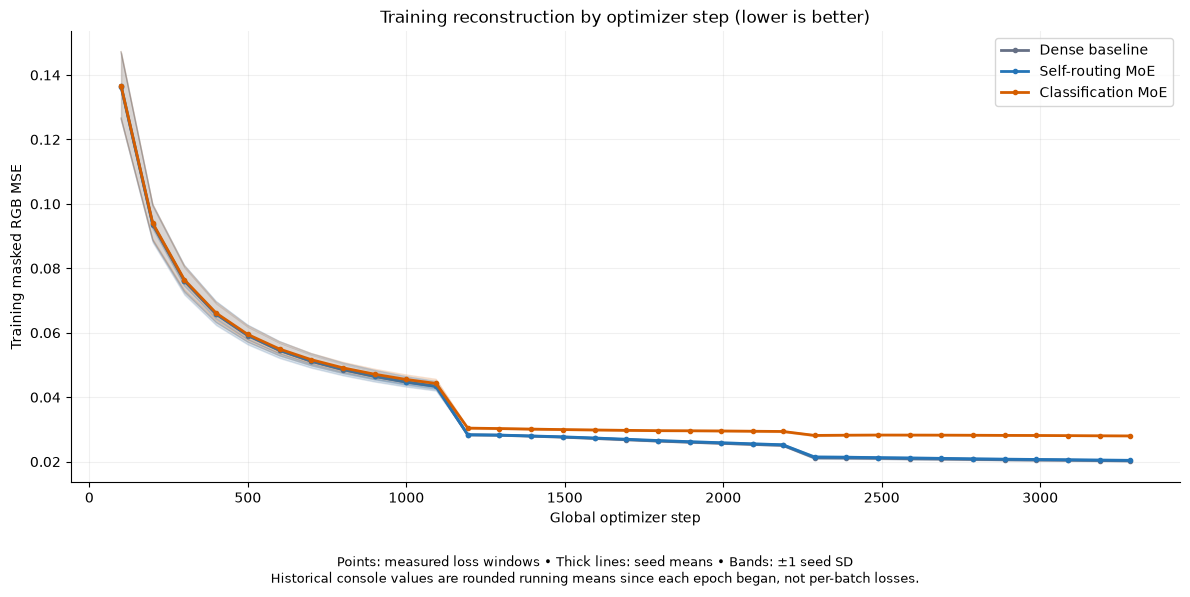

Training curve: 297 saved observations across model/seed traces.


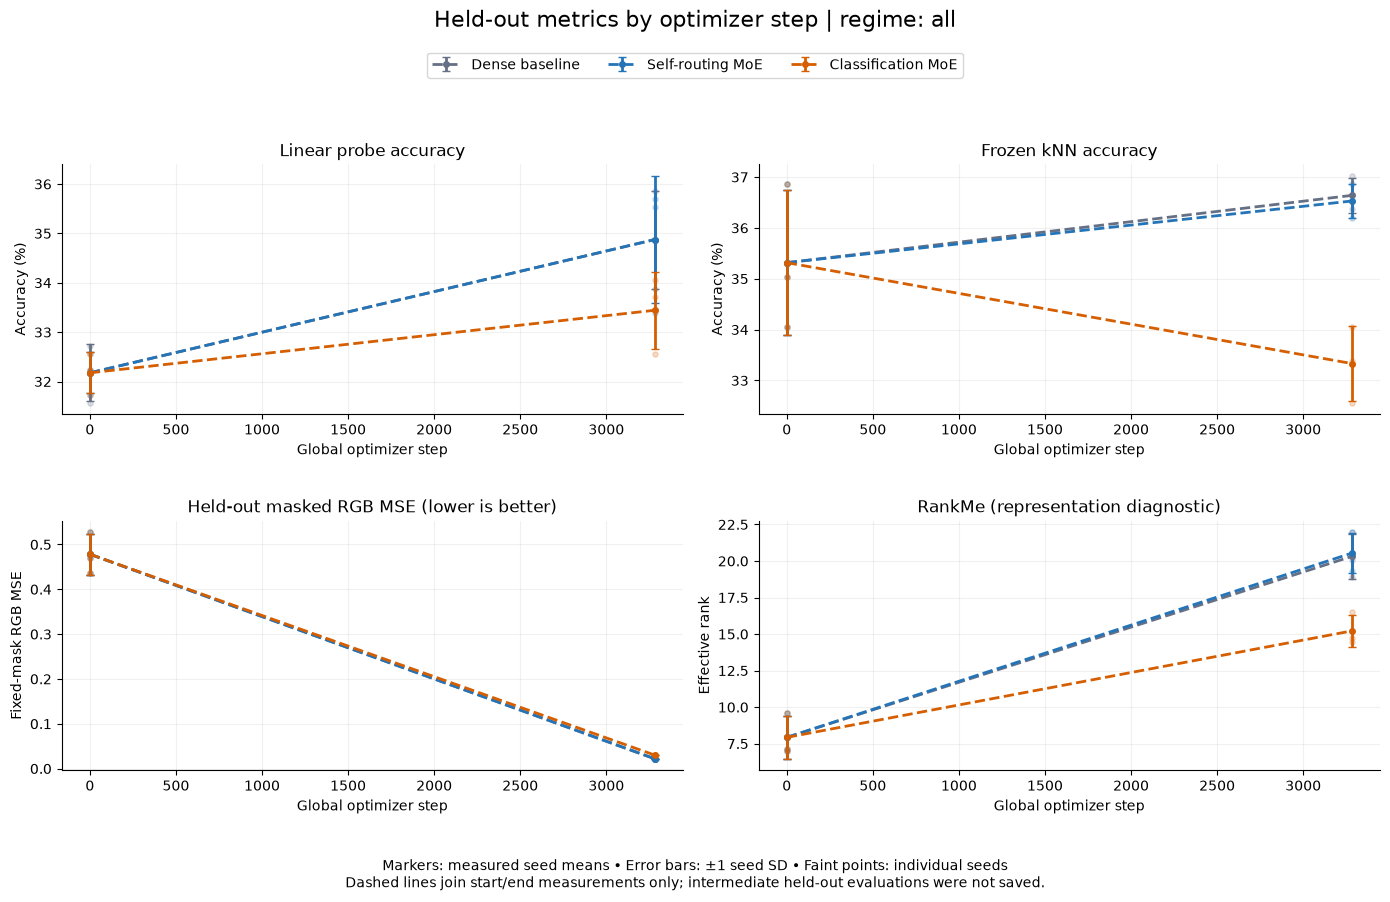

Saved step-based figures: C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-comparison\20261028T174434487283Z


In [17]:
import json
import re as step_re
from pathlib import Path

import matplotlib.pyplot as step_plt
import pandas as pd
from IPython.display import display as show

# Run alone on saved data, with no training; choose all/daytime/dawn/dusk/night.
step_curves_run_dir = None
step_curves_regime = "all"
step_curves_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir())
if step_curves_run_dir is None:
    if "run_dir" in globals():
        step_curves_run_dir = Path(run_dir)
    else:
        step_curves_files = sorted((step_curves_root / "outputs/moe-router-comparison").glob("*/training.csv"))
        if not step_curves_files:
            raise FileNotFoundError("No saved training history. Set step_curves_run_dir.")
        step_curves_run_dir = step_curves_files[-1].parent
step_curves_run_dir = Path(step_curves_run_dir)
step_history = pd.read_csv(step_curves_run_dir / "training.csv")
step_external = pd.read_csv(step_curves_run_dir / "external_metrics.csv")
if step_history.duplicated(["arm", "seed", "epoch"]).any():
    raise ValueError("Ambiguous duplicate training records.")
step_totals = step_history.groupby(["arm", "seed"])["updates"].sum()
step_arms = ["dense", "self_moe", "class_moe"]
step_names = ["Dense baseline", "Self-routing MoE", "Classification MoE"]
step_colors = ["#667085", "#2474b7", "#d55e00"]
step_loss_frames = []
step_logged_pairs = set()
for step_path in sorted(step_curves_run_dir.glob("seed_*/*/training_steps.csv")):
    step_frame = pd.read_csv(step_path)
    step_frame["measurement_source"] = "step_window"
    step_loss_frames.append(step_frame)
    step_logged_pairs.update(zip(step_frame["arm"], step_frame["seed"], strict=True))

# Recover actual 100-step running-loss messages from the saved notebook for legacy runs.
step_saved_notebook = json.loads(
    (step_curves_root / "notebooks/moe_router_classification_comparison.ipynb").read_text(encoding="utf-8")
)
step_console = {}
for step_cell in step_saved_notebook["cells"]:
    step_console[step_cell["id"]] = "".join(
        "".join(output.get("text", [])) for output in step_cell.get("outputs", []) if output["output_type"] == "stream"
    )
step_recovered = []
step_console_run = step_console.get("8e610c70", "").split("outputs: ", 1)[-1].strip()
if step_console_run and Path(step_console_run).resolve() == step_curves_run_dir.resolve():
    step_pattern = r"(dense|self_moe|class_moe) seed (\d+), epoch (\d+), step (\d+): RGB MSE ([\d.eE+-]+)"
    for step_arm, step_seed_text, step_epoch_text, step_local_text, step_mse in step_re.findall(
        step_pattern, step_console.get("2f954299", "")
    ):
        step_seed, step_epoch, step_local = int(step_seed_text), int(step_epoch_text), int(step_local_text)
        if (step_arm, step_seed) in step_logged_pairs:
            continue
        step_prior = step_history.loc[
            step_history["arm"].eq(step_arm)
            & step_history["seed"].eq(step_seed)
            & step_history["epoch"].lt(step_epoch),
            "updates",
        ].sum()
        step_recovered.append(
            {
                "arm": step_arm,
                "seed": step_seed,
                "global_step": int(step_prior + step_local),
                "reconstruction": float(step_mse),
                "measurement_source": "saved_console_running_mean",
            }
        )
    step_recovered_pairs = {(row["arm"], row["seed"]) for row in step_recovered}
    for step_row in step_history.sort_values("epoch").itertuples():
        if (step_row.arm, step_row.seed) not in step_recovered_pairs:
            continue
        step_prior = step_history.loc[
            step_history["arm"].eq(step_row.arm)
            & step_history["seed"].eq(step_row.seed)
            & step_history["epoch"].le(step_row.epoch),
            "updates",
        ].sum()
        step_recovered.append(
            {
                "arm": step_row.arm,
                "seed": step_row.seed,
                "global_step": int(step_prior),
                "reconstruction": step_row.reconstruction,
                "measurement_source": "saved_console_running_mean",
            }
        )
if step_recovered:
    step_loss_frames.append(pd.DataFrame(step_recovered))
step_saved_points_path = step_curves_run_dir / "training_curve_step_points.csv"
if step_saved_points_path.exists():
    step_previous = pd.read_csv(step_saved_points_path)
    step_active_pairs = {(row.arm, row.seed) for frame in step_loss_frames for row in frame.itertuples()}
    step_previous = step_previous.loc[
        [(row.arm, row.seed) not in step_active_pairs for row in step_previous.itertuples()]
    ]
    if not step_previous.empty:
        step_loss_frames.append(step_previous)
if step_loss_frames:
    step_losses = pd.concat(step_loss_frames, ignore_index=True)
    step_losses = step_losses.drop_duplicates(["arm", "seed", "global_step"], keep="last")
    step_losses = step_losses.sort_values(["arm", "seed", "global_step"])
    step_losses.to_csv(step_curves_run_dir / "training_curve_step_points.csv", index=False)
    step_loss_fig, step_loss_ax = step_plt.subplots(figsize=(12, 6))
    for step_arm, step_name, step_color in zip(step_arms, step_names, step_colors, strict=True):
        step_part = step_losses.loc[step_losses["arm"] == step_arm]
        for _, step_seed_rows in step_part.groupby("seed"):
            step_loss_ax.plot(
                step_seed_rows["global_step"],
                step_seed_rows["reconstruction"],
                color=step_color,
                alpha=0.18,
                linewidth=1,
            )
        step_summary = step_part.groupby("global_step")["reconstruction"].agg(["mean", "std"])
        step_loss_ax.plot(
            step_summary.index, step_summary["mean"], "o-", color=step_color, label=step_name, linewidth=2, markersize=3
        )
        step_loss_ax.fill_between(
            step_summary.index,
            step_summary["mean"] - step_summary["std"].fillna(0),
            step_summary["mean"] + step_summary["std"].fillna(0),
            color=step_color,
            alpha=0.1,
        )
    step_loss_ax.set(
        title="Training reconstruction by optimizer step (lower is better)",
        xlabel="Global optimizer step",
        ylabel="Training masked RGB MSE",
    )
    step_loss_ax.legend()
    step_loss_ax.grid(alpha=0.18)
    step_loss_ax.spines[["top", "right"]].set_visible(False)
    step_loss_note = "Points: measured loss windows • Thick lines: seed means • Bands: ±1 seed SD"
    if step_losses["measurement_source"].eq("saved_console_running_mean").any():
        step_loss_note += (
            "\nHistorical console values are rounded running means since each epoch began, not per-batch losses."
        )
    step_loss_fig.text(0.5, 0.02, step_loss_note, ha="center", fontsize=9)
    step_loss_fig.tight_layout(rect=(0, 0.09, 1, 1))
    for step_suffix in ["png", "pdf"]:
        step_loss_fig.savefig(step_curves_run_dir / f"training_reconstruction_steps.{step_suffix}", dpi=160)
    show(step_loss_fig)
    step_plt.close(step_loss_fig)
    print(f"Training curve: {len(step_losses)} saved observations across model/seed traces.")
else:
    print("This run has no saved step losses or matching console messages. Future training logs loss windows.")

step_points = step_external.loc[step_external["stage"].isin(["initial", "final"])].copy()
step_points["global_step"] = [
    0 if row.stage == "initial" else int(step_totals.loc[(row.arm, row.seed)]) for row in step_points.itertuples()
]
step_metric_path = step_curves_run_dir / "external_metrics_by_step.csv"
if step_metric_path.exists():
    step_logged = pd.read_csv(step_metric_path)
    if step_logged.duplicated(["arm", "seed", "regime", "global_step"]).any():
        raise ValueError("Duplicate held-out step measurements.")
    step_points = pd.concat([step_points, step_logged], ignore_index=True)
step_points = step_points.drop_duplicates(["arm", "seed", "regime", "global_step"], keep="last")
step_points = step_points.sort_values(["arm", "seed", "regime", "global_step"])
step_points.to_csv(step_curves_run_dir / "external_training_curve_step_points.csv", index=False)
step_selected = step_points.loc[step_points["regime"] == step_curves_regime]
if step_selected.empty:
    raise ValueError(f"No held-out metrics for regime: {step_curves_regime}")
step_specs = [
    ("linear_accuracy", "Linear probe accuracy", 100.0, "Accuracy (%)"),
    ("knn_accuracy", "Frozen kNN accuracy", 100.0, "Accuracy (%)"),
    ("masked_rgb_mse", "Held-out masked RGB MSE (lower is better)", 1.0, "Fixed-mask RGB MSE"),
    ("rankme", "RankMe (representation diagnostic)", 1.0, "Effective rank"),
]
step_fig, step_axes = step_plt.subplots(2, 2, figsize=(14, 9))
step_endpoint_only = False
for step_ax, (step_metric, step_title, step_scale, step_unit) in zip(step_axes.flat, step_specs, strict=True):
    for step_arm, step_name, step_color in zip(step_arms, step_names, step_colors, strict=True):
        step_part = step_selected.loc[step_selected["arm"] == step_arm]
        for _, step_seed_rows in step_part.groupby("seed"):
            step_ax.scatter(
                step_seed_rows["global_step"],
                step_seed_rows[step_metric] * step_scale,
                color=step_color,
                alpha=0.22,
                s=14,
                zorder=2,
            )
        step_summary = step_part.groupby("global_step")[step_metric].agg(["mean", "std"]).sort_index()
        step_x = step_summary.index.to_numpy(dtype=int)
        step_y = step_summary["mean"].to_numpy() * step_scale
        step_sd = step_summary["std"].fillna(0).to_numpy() * step_scale
        step_sparse = len(step_x) <= 2
        step_endpoint_only = step_endpoint_only or step_sparse
        step_ax.errorbar(
            step_x,
            step_y,
            yerr=step_sd,
            fmt="o--" if step_sparse else "o-",
            color=step_color,
            label=step_name,
            capsize=3,
            markersize=4,
            linewidth=2,
        )
    step_ax.set(title=step_title, xlabel="Global optimizer step", ylabel=step_unit)
    step_ax.grid(alpha=0.18)
    step_ax.spines[["top", "right"]].set_visible(False)
step_handles, step_labels = step_axes[0, 0].get_legend_handles_labels()
step_fig.legend(step_handles, step_labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=3)
step_fig.suptitle(f"Held-out metrics by optimizer step | regime: {step_curves_regime}", fontsize=16, y=0.99)
step_note = "Markers: measured seed means • Error bars: ±1 seed SD • Faint points: individual seeds"
if step_endpoint_only:
    step_note += "\nDashed lines join start/end measurements only; intermediate held-out evaluations were not saved."
step_fig.text(0.5, 0.015, step_note, ha="center", fontsize=10)
step_fig.tight_layout(rect=(0, 0.08, 1, 0.90), h_pad=3, w_pad=2)
step_slug = step_curves_regime.replace("/", "-")
for step_suffix in ["png", "pdf"]:
    step_fig.savefig(step_curves_run_dir / f"heldout_training_steps_{step_slug}.{step_suffix}", dpi=160)
show(step_fig)
step_plt.close(step_fig)
print(f"Saved step-based figures: {step_curves_run_dir}")

## Paired results: dense baseline and classification versus self-routing

Accuracy/F1 deltas are percentage points; reconstruction and rank deltas retain their original units. Read signs using each metric's direction. The paired intervals below describe variation across the chosen training seeds. One seed has no estimated interval. Compare initial-to-final changes as well as endpoints; a checkpoint with a better reconstruction error can still have worse scene probes. There is no single combined “MoE performance” score.


### Readable performance comparisons

The first dashboard shows final held-out **linear-probe accuracy, frozen kNN accuracy, masked RGB MSE, and RankMe** for the dense baseline and both MoEs, overall and by regime. Bars are seed means, black points show each seed, and error bars are ±1 standard deviation across training seeds. Every bar is labeled with its value and every regime shows its query count. RGB MSE is multiplied by 1,000 for readable axes; the underlying saved metrics stay unchanged.

The second dashboard isolates the experimental question: **classification MoE minus self-routing MoE, paired by training seed**. The zero line means no difference. Higher accuracy is better; lower RGB MSE is better. Higher RankMe means higher embedding effective rank, which does not establish better classification performance. Error bars here describe the paired differences, rather than subtracting independent error bars. SD bars are not confidence intervals. With one seed, variability bars are omitted.

Run this cell on saved metrics without retraining. It uses the active `run_dir`, or the latest saved comparison when run alone. Set `performance_run_dir` to choose a run. Both figures are embedded below and saved as PNG/PDF alongside summary CSVs.


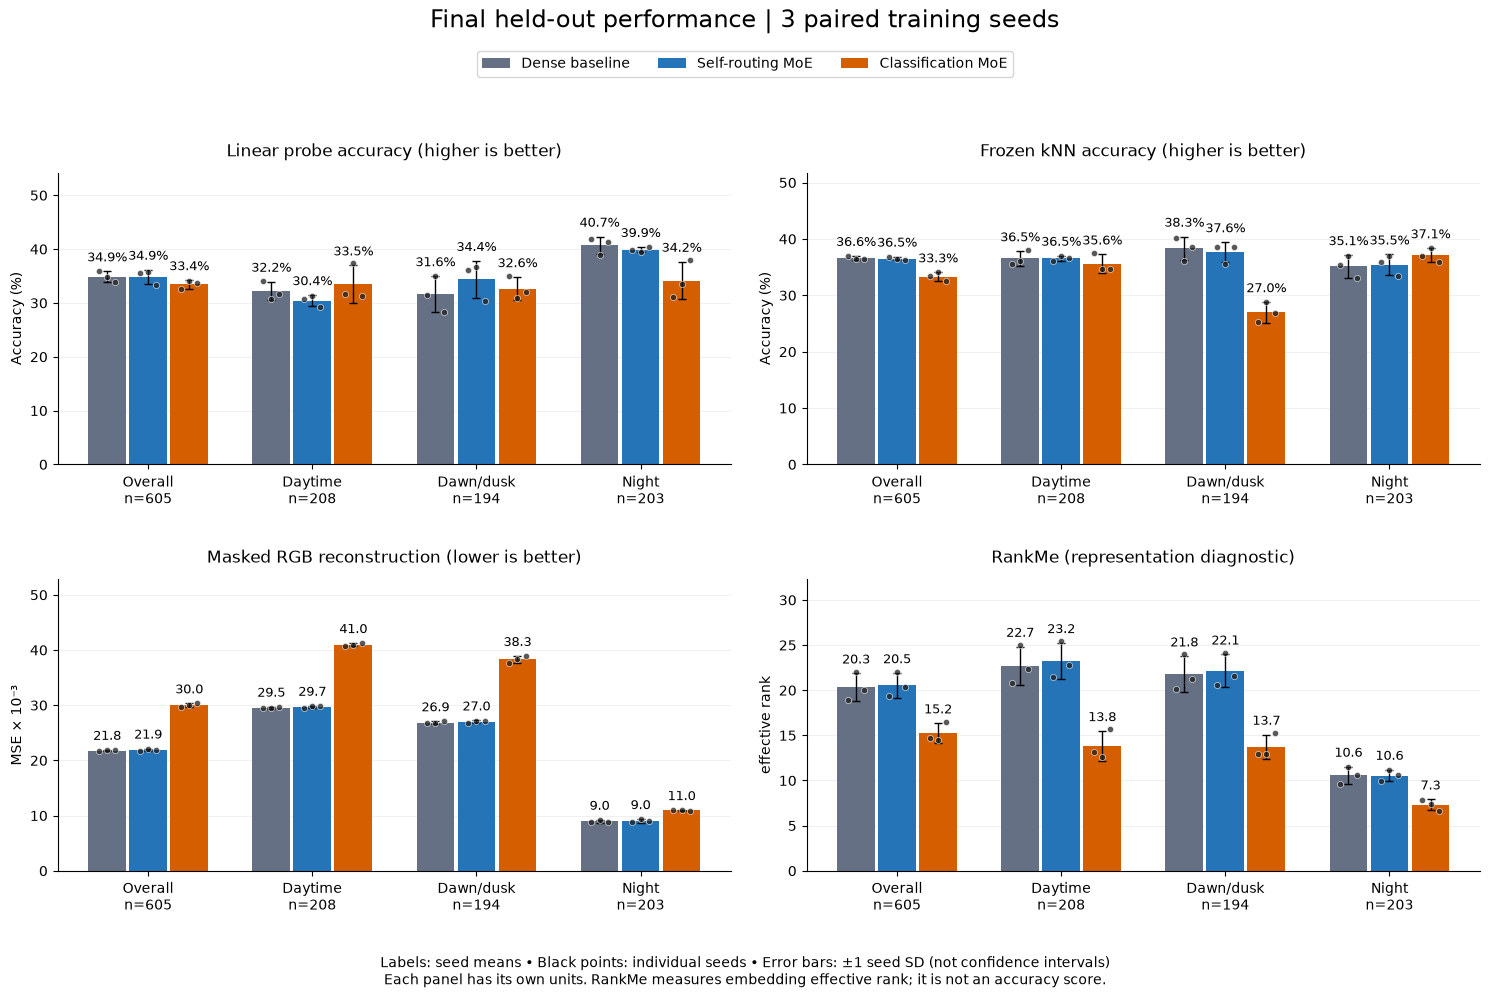

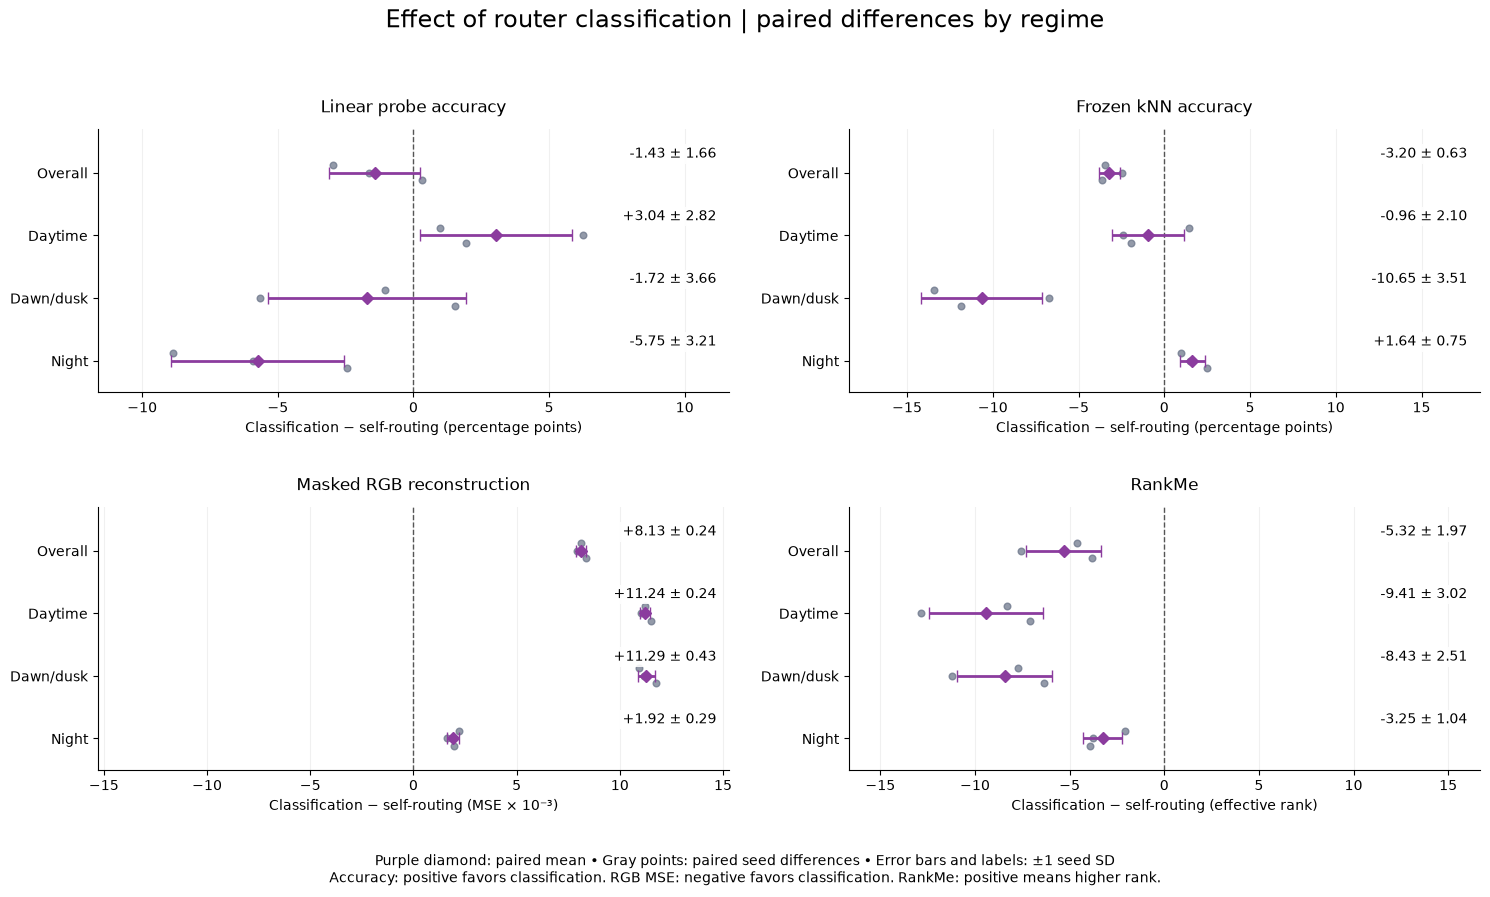

Rendered saved metrics from run: 20261028T174434487283Z
C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-comparison\20261028T174434487283Z\external_performance_by_regime.png
C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-comparison\20261028T174434487283Z\external_classification_vs_self.png


In [15]:
from pathlib import Path

import matplotlib.pyplot as performance_plt
import numpy as np
import pandas as pd
from IPython.display import display as show

# Set a saved run folder here to redraw these figures without training.
performance_run_dir = None
if performance_run_dir is None:
    if "run_dir" in globals():
        performance_run_dir = Path(run_dir)
    else:
        performance_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir())
        performance_files = sorted((performance_root / "outputs/moe-router-comparison").glob("*/external_metrics.csv"))
        if not performance_files:
            raise FileNotFoundError("No saved external metrics. Run evaluation or set performance_run_dir.")
        performance_run_dir = performance_files[-1].parent
performance_run_dir = Path(performance_run_dir)
performance_data = pd.read_csv(performance_run_dir / "external_metrics.csv")
performance_regimes = ["all", "daytime", "dawn/dusk", "night"]
performance_regime_labels = ["Overall", "Daytime", "Dawn/dusk", "Night"]
performance_arms = ["dense", "self_moe", "class_moe"]
performance_arm_labels = ["Dense baseline", "Self-routing MoE", "Classification MoE"]
performance_colors = ["#667085", "#2474b7", "#d55e00"]
performance_specs = [
    ("linear_accuracy", "Linear probe accuracy", 100.0, "%", "higher is better"),
    ("knn_accuracy", "Frozen kNN accuracy", 100.0, "%", "higher is better"),
    ("masked_rgb_mse", "Masked RGB reconstruction", 1000.0, "MSE × 10⁻³", "lower is better"),
    ("rankme", "RankMe", 1.0, "effective rank", "representation diagnostic"),
]
performance_final = performance_data.loc[
    performance_data["stage"].eq("final")
    & performance_data["arm"].isin(performance_arms)
    & performance_data["regime"].isin(performance_regimes)
].copy()
performance_seeds = sorted(performance_final["seed"].unique())
performance_index = pd.MultiIndex.from_product(
    [performance_seeds, performance_arms, performance_regimes], names=["seed", "arm", "regime"]
)
performance_panel = performance_final.set_index(["seed", "arm", "regime"])
if not performance_seeds or not performance_panel.index.is_unique:
    raise ValueError("Expected unique final seed/arm/regime results.")
if not performance_index.isin(performance_panel.index).all():
    raise ValueError("Each arm needs the same seeds and regimes for a paired comparison.")
performance_panel = performance_panel.reindex(performance_index)
performance_columns = [spec[0] for spec in performance_specs]
if not np.isfinite(performance_panel[performance_columns].to_numpy()).all():
    raise ValueError("Missing or nonfinite performance values.")
if (performance_final.groupby("regime")["images"].nunique() != 1).any():
    raise ValueError("Compared arms must use equal held-out sample counts within each regime.")
performance_counts = performance_final.groupby("regime")["images"].first().reindex(performance_regimes)
performance_fig, performance_axes = performance_plt.subplots(2, 2, figsize=(15, 10))
performance_summary_rows = []
for performance_ax, (
    performance_metric,
    performance_title,
    performance_scale,
    performance_unit,
    performance_direction,
) in zip(performance_axes.flat, performance_specs, strict=True):
    performance_max = 0.0
    for arm_index, (performance_arm, performance_label, performance_color) in enumerate(
        zip(performance_arms, performance_arm_labels, performance_colors, strict=True)
    ):
        performance_values = (
            performance_panel.xs(performance_arm, level="arm")[performance_metric]
            .unstack("regime")
            .reindex(index=performance_seeds, columns=performance_regimes)
            .to_numpy()
            * performance_scale
        )
        performance_means = performance_values.mean(axis=0)
        performance_sd = (
            performance_values.std(axis=0, ddof=1) if len(performance_seeds) > 1 else np.zeros(len(performance_regimes))
        )
        performance_x = np.arange(len(performance_regimes)) + (arm_index - 1) * 0.25
        performance_bars = performance_ax.bar(
            performance_x,
            performance_means,
            width=0.23,
            yerr=performance_sd if len(performance_seeds) > 1 else None,
            capsize=3,
            color=performance_color,
            label=performance_label,
            error_kw={"elinewidth": 1, "capthick": 1},
            zorder=2,
        )
        performance_ax.bar_label(
            performance_bars,
            labels=[f"{v:.1f}{'%' if performance_unit == '%' else ''}" for v in performance_means],
            padding=5,
            fontsize=9,
        )
        for seed_index, _performance_seed in enumerate(performance_seeds):
            performance_jitter = 0.10 * (seed_index / max(1, len(performance_seeds) - 1) - 0.5)
            performance_ax.scatter(
                performance_x + performance_jitter,
                performance_values[seed_index],
                color="#202020",
                edgecolors="white",
                linewidths=0.5,
                alpha=0.75,
                s=20,
                zorder=4,
            )
        performance_max = max(performance_max, float((performance_means + performance_sd).max()))
        for regime_index, performance_regime in enumerate(performance_regimes):
            performance_summary_rows.append(
                {
                    "arm": performance_arm,
                    "regime": performance_regime,
                    "metric": performance_metric,
                    "seeds": len(performance_seeds),
                    "query_images": int(performance_counts.iloc[regime_index]),
                    "mean": performance_means[regime_index] / performance_scale,
                    "seed_sd": performance_sd[regime_index] / performance_scale
                    if len(performance_seeds) > 1
                    else np.nan,
                }
            )
    performance_ax.set_title(f"{performance_title} ({performance_direction})", fontsize=12, pad=12)
    performance_ax.set_ylabel("Accuracy (%)" if performance_unit == "%" else performance_unit)
    performance_ax.set_xticks(
        range(len(performance_regimes)),
        [f"{name}\nn={int(count)}" for name, count in zip(performance_regime_labels, performance_counts, strict=True)],
    )
    performance_ax.set_ylim(0, min(100, performance_max * 1.28) if performance_unit == "%" else performance_max * 1.28)
    performance_ax.yaxis.grid(True, alpha=0.18, zorder=0)
    performance_ax.spines[["top", "right"]].set_visible(False)
performance_fig.suptitle(
    f"Final held-out performance | {len(performance_seeds)} paired training seeds", fontsize=17, y=0.99
)
performance_handles, performance_labels = performance_axes[0, 0].get_legend_handles_labels()
performance_fig.legend(performance_handles, performance_labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=3)
performance_fig.text(
    0.5,
    0.015,
    "Labels: seed means • Black points: individual seeds • Error bars: ±1 seed SD (not confidence intervals)\n"
    "Each panel has its own units. RankMe measures embedding effective rank; it is not an accuracy score.",
    ha="center",
    fontsize=10,
)
performance_fig.tight_layout(rect=(0, 0.07, 1, 0.91), h_pad=3, w_pad=2)
for performance_suffix in ["png", "pdf"]:
    performance_fig.savefig(performance_run_dir / f"external_performance_by_regime.{performance_suffix}", dpi=180)
pd.DataFrame(performance_summary_rows).to_csv(performance_run_dir / "external_performance_summary.csv", index=False)
show(performance_fig)
performance_plt.close(performance_fig)

# Pair each classification result with the same self-routing training seed.
performance_delta_fig, performance_delta_axes = performance_plt.subplots(2, 2, figsize=(15, 9))
performance_delta_rows = []
for performance_ax, (
    performance_metric,
    performance_title,
    performance_scale,
    performance_unit,
    _performance_direction,
) in zip(performance_delta_axes.flat, performance_specs, strict=True):
    performance_self = performance_panel.xs("self_moe", level="arm")[performance_metric].unstack("regime")
    performance_class = performance_panel.xs("class_moe", level="arm")[performance_metric].unstack("regime")
    performance_deltas = (performance_class - performance_self).reindex(
        index=performance_seeds, columns=performance_regimes
    ) * performance_scale
    performance_delta_mean = performance_deltas.mean(axis=0).to_numpy()
    performance_delta_sd = (
        performance_deltas.std(axis=0, ddof=1).to_numpy()
        if len(performance_seeds) > 1
        else np.zeros(len(performance_regimes))
    )
    performance_y = np.arange(len(performance_regimes))
    performance_ax.axvline(0, color="#555555", linestyle="--", linewidth=1)
    for seed_index, performance_seed in enumerate(performance_seeds):
        performance_jitter = 0.24 * (seed_index / max(1, len(performance_seeds) - 1) - 0.5)
        performance_ax.scatter(
            performance_deltas.loc[performance_seed],
            performance_y + performance_jitter,
            color="#667085",
            alpha=0.7,
            s=23,
            zorder=3,
        )
        for performance_regime in performance_regimes:
            performance_delta_rows.append(
                {
                    "seed": performance_seed,
                    "regime": performance_regime,
                    "metric": performance_metric,
                    "class_minus_self": performance_deltas.loc[performance_seed, performance_regime]
                    / performance_scale,
                }
            )
    performance_ax.errorbar(
        performance_delta_mean,
        performance_y,
        xerr=performance_delta_sd if len(performance_seeds) > 1 else None,
        fmt="D",
        color="#8b3c9e",
        markersize=6,
        capsize=4,
        linewidth=2,
        zorder=4,
    )
    performance_limit = (
        max(
            float(np.abs(performance_deltas.to_numpy()).max()),
            float((np.abs(performance_delta_mean) + performance_delta_sd).max()),
            0.01,
        )
        * 1.3
    )
    performance_ax.set_xlim(-performance_limit, performance_limit)
    performance_ax.set_ylim(3.5, -0.7)
    performance_ax.set_yticks(performance_y, performance_regime_labels)
    performance_delta_unit = "percentage points" if performance_unit == "%" else performance_unit
    performance_ax.set_xlabel(f"Classification − self-routing ({performance_delta_unit})")
    performance_ax.set_title(performance_title, fontsize=12, pad=12)
    performance_ax.spines[["top", "right"]].set_visible(False)
    performance_ax.xaxis.grid(True, alpha=0.18)
    for regime_index, performance_value in enumerate(performance_delta_mean):
        performance_sd_text = f" ± {performance_delta_sd[regime_index]:.2f}" if len(performance_seeds) > 1 else ""
        performance_ax.text(
            0.98,
            regime_index - 0.30,
            f"{performance_value:+.2f}{performance_sd_text}",
            transform=performance_ax.get_yaxis_transform(),
            ha="right",
            va="center",
            fontsize=10,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 2},
        )
performance_delta_fig.suptitle("Effect of router classification | paired differences by regime", fontsize=17, y=0.99)
performance_delta_fig.text(
    0.5,
    0.02,
    "Purple diamond: paired mean • Gray points: paired seed differences • Error bars and labels: ±1 seed SD\n"
    "Accuracy: positive favors classification. RGB MSE: negative favors classification. "
    "RankMe: positive means higher rank.",
    ha="center",
    fontsize=10,
)
performance_delta_fig.tight_layout(rect=(0, 0.08, 1, 0.95), h_pad=3, w_pad=2)
for performance_suffix in ["png", "pdf"]:
    performance_delta_fig.savefig(
        performance_run_dir / f"external_classification_vs_self.{performance_suffix}", dpi=180
    )
pd.DataFrame(performance_delta_rows).to_csv(performance_run_dir / "external_classification_vs_self.csv", index=False)
show(performance_delta_fig)
performance_plt.close(performance_delta_fig)
print(f"Rendered saved metrics from run: {performance_run_dir.name}")
print(performance_run_dir / "external_performance_by_regime.png")
print(performance_run_dir / "external_classification_vs_self.png")

,regime,comparison,metric,seeds,mean_delta,seed_std,ci95_low,ci95_high
5,all,class_moe-self_moe,knn_accuracy,3,-3.195592,0.625775,-4.750104,-1.641081
6,all,class_moe-self_moe,linear_accuracy,3,-1.432507,1.663875,-5.565802,2.700789
7,all,class_moe-self_moe,masked_rgb_mse,3,0.008128,0.000239,0.007536,0.008721
8,all,class_moe-self_moe,rankme,3,-5.321506,1.973691,-10.224427,-0.418585
9,all,class_moe-self_moe,rankme_normalized,3,-0.055432,0.020559,-0.106504,-0.004360


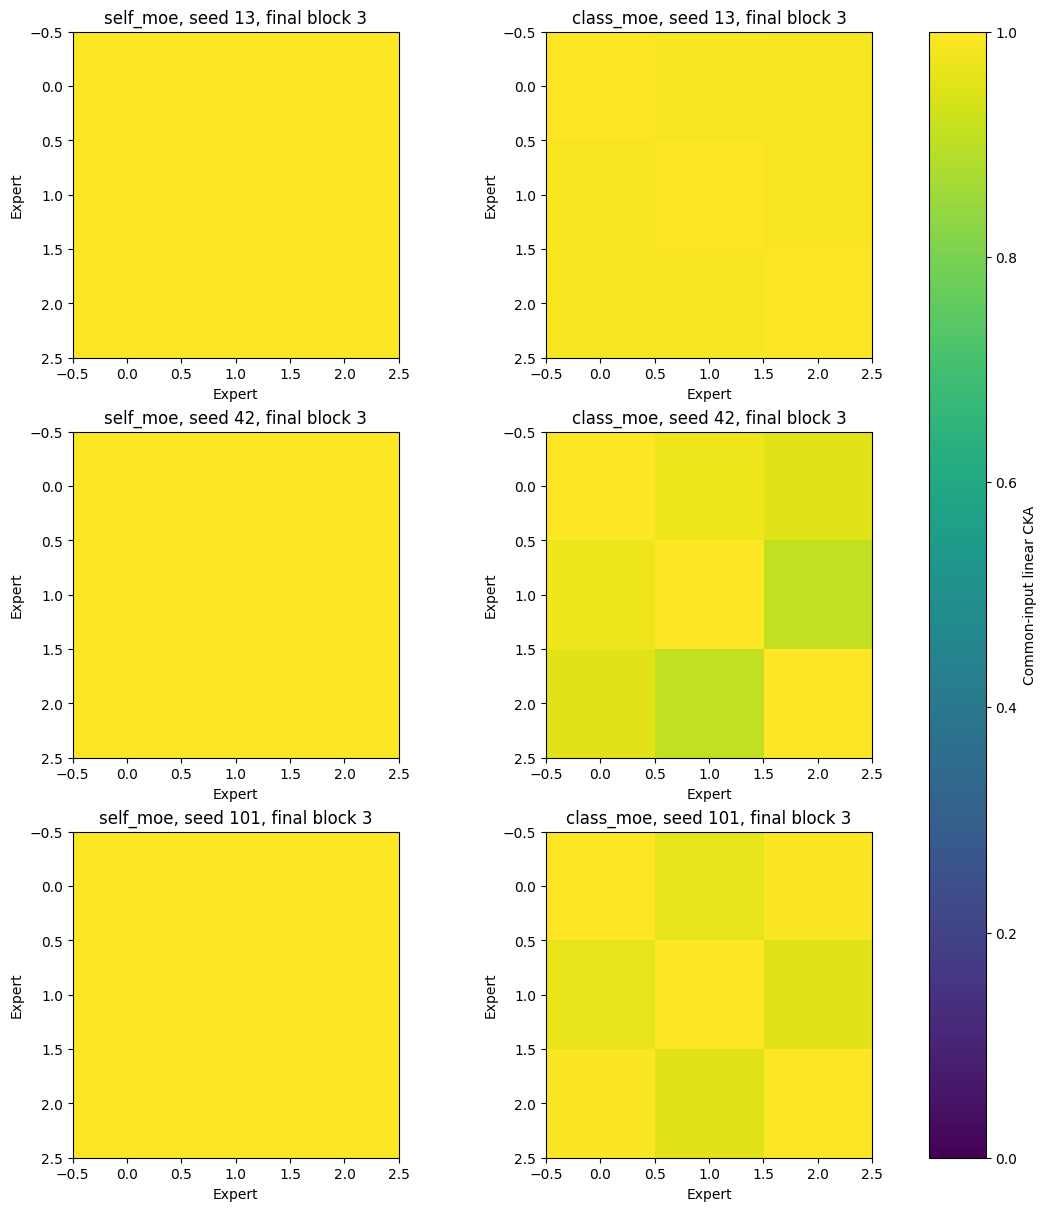

,arm,seed,block,regime,images,entropy_nats,entropy_normalized
0,self_moe,13,3,all,512,1.095366,0.997045
1,self_moe,13,3,daytime,208,1.092545,0.994478
2,self_moe,13,3,dawn/dusk,130,1.096972,0.998507
3,self_moe,13,3,night,174,1.094143,0.995932
4,class_moe,13,3,all,512,1.098568,0.999960
5,class_moe,13,3,daytime,208,0.656593,0.597657
6,class_moe,13,3,dawn/dusk,130,0.499949,0.455073
7,class_moe,13,3,night,174,0.171307,0.155930
8,self_moe,42,3,all,512,1.091495,0.993521
9,self_moe,42,3,daytime,208,1.093551,0.995393


,arm,seed,block,regime,expert,selected_tokens,total_selected_tokens,token_activation_frequency,image_activation_frequency,mean_probability
0,self_moe,13,3,all,0,10692,32768,0.326294,1.000000,0.333868
1,self_moe,13,3,all,1,12102,32768,0.369324,1.000000,0.332736
2,self_moe,13,3,all,2,9974,32768,0.304382,1.000000,0.333396
3,self_moe,13,3,daytime,0,4553,13312,0.342022,1.000000,0.334478
4,self_moe,13,3,daytime,1,4965,13312,0.372972,1.000000,0.333039
...,...,...,...,...,...,...,...,...,...,...
67,class_moe,101,3,dawn/dusk,1,7185,8320,0.863582,0.930769,0.714861
68,class_moe,101,3,dawn/dusk,2,144,8320,0.017308,0.030769,0.044396
69,class_moe,101,3,night,0,0,11136,0.000000,0.000000,0.007331
70,class_moe,101,3,night,1,127,11136,0.011404,0.017241,0.031355


In [11]:
metric_names = ["linear_accuracy", "knn_accuracy", "masked_rgb_mse", "rankme", "rankme_normalized"]
final = external_metrics.loc[external_metrics["stage"] == "final"]
paired = []
for (seed, regime), rows in final.groupby(["seed", "regime"]):
    indexed = rows.set_index("arm")
    for metric in metric_names:
        scale = 100 if metric.endswith("accuracy") else 1
        for arm in ["self_moe", "class_moe"]:
            paired.append(
                {
                    "seed": seed,
                    "regime": regime,
                    "comparison": f"{arm}-dense",
                    "metric": metric,
                    "delta": scale * (indexed.loc[arm, metric] - indexed.loc["dense", metric]),
                }
            )
        paired.append(
            {
                "seed": seed,
                "regime": regime,
                "comparison": "class_moe-self_moe",
                "metric": metric,
                "delta": scale * (indexed.loc["class_moe", metric] - indexed.loc["self_moe", metric]),
            }
        )
paired_deltas = pd.DataFrame(paired)
paired_deltas.to_csv(run_dir / "paired_deltas.csv", index=False)
summary = []
for (regime, comparison, metric), rows in paired_deltas.groupby(["regime", "comparison", "metric"]):
    values = rows["delta"].to_numpy()
    spread = float(values.std(ddof=1)) if len(values) > 1 else float("nan")
    half = student_t.ppf(0.975, len(values) - 1) * spread / np.sqrt(len(values)) if len(values) > 1 else float("nan")
    summary.append(
        {
            "regime": regime,
            "comparison": comparison,
            "metric": metric,
            "seeds": len(values),
            "mean_delta": values.mean(),
            "seed_std": spread,
            "ci95_low": values.mean() - half,
            "ci95_high": values.mean() + half,
        }
    )
paired_summary = pd.DataFrame(summary)
paired_summary.to_csv(run_dir / "paired_summary.csv", index=False)
show(paired_summary.loc[(paired_summary["regime"] == "all") & (paired_summary["comparison"] == "class_moe-self_moe")])
fig, axes = plt.subplots(len(seeds), 2, figsize=(11, 4 * len(seeds)), squeeze=False, constrained_layout=True)
for row, seed in enumerate(seeds):
    for column, arm in enumerate(["self_moe", "class_moe"]):
        matrix = cka_metrics.loc[
            (cka_metrics["seed"] == seed) & (cka_metrics["kind"] == "within_arm") & (cka_metrics["arm"] == arm)
        ]
        matrix = matrix.pivot(index="expert_i", columns="expert_j", values="cka")
        image = axes[row, column].imshow(matrix, vmin=0, vmax=1, cmap="viridis")
        axes[row, column].set(
            title=f"{arm}, seed {seed}, final block {analysis_block}", xlabel="Expert", ylabel="Expert"
        )
fig.colorbar(image, ax=axes.ravel().tolist(), label="Common-input linear CKA")
fig.savefig(run_dir / "expert_cka.png", dpi=130)
plt.show()
show(entropy_metrics)
show(activation_metrics)

## Expert distribution by regime

Rows are the image regimes; columns are experts. Each value is the **fraction of spatial top-1 dispatches within that regime**, excluding CLS, in the final MoE block on the fixed held-out expert probe panel. Each row sums to 100%. Both arms use the same 0–100% scale. These are actual selected-expert shares, rather than soft router probabilities or image-any-activation rates.

Seeds are shown separately: self-routing expert IDs have no fixed regime meaning and are not aligned across seeds or arms. For the classification arm, E0/E1/E2 are supervised toward daytime/dawn-dusk/night. Missing regimes appear as `n/a`, not zero. The dense baseline has no experts.

This cell can also run alone on saved statistics without retraining. It uses the active `run_dir` when available, otherwise the latest saved comparison statistics. Set `distribution_run_dir` explicitly to choose another run. PNG, PDF, and CSV are saved beside the run metrics.

**Weather and scene detail.** The additional heatmaps below use BDD's native `timeofday`, `weather`,
and `scene` attributes. They compare time × weather, time × scene, and observed time × weather × scene
combinations. The detailed evaluation defaults to all 605 held-out query images from this run,
including rare scenes beyond the original 512-image expert/CKA panel above. Both arms and all
training seeds use exactly the same selected images, and no training or classifier fitting occurs.
Use `condition_use_all_query=False` to reproduce the smaller original panel instead.

Every row shows its image count. Groups with fewer than `condition_min_images=5` images, and absent
groups, are gray rather than displayed as zero activity. `undefined` weather remains its own BDD
label. Pairwise panels show absent combinations explicitly; joint panels show observed combinations,
including sparse ones. Percentages use the same 0–100% scale throughout. All numeric summaries,
including sparse groups, are exported to CSV.

The routing cache includes all trained seeds; detailed figures default to the first seed (13 for
this run), matching the videos. Set `condition_plot_seeds=condition_seeds` to show each seed
separately. Self-routing expert IDs are not aligned across seeds or given automatic condition names.
The default metric is actual spatial top-1 dispatch share; choose `condition_metric="mean_probability"`
to show continuous router preferences instead. The existing models, coarse heatmap, and videos are preserved.


Saved regime heatmap from run: 20261028T174434487283Z
C:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-comparison\20261028T174434487283Z\expert_distribution_by_regime.png


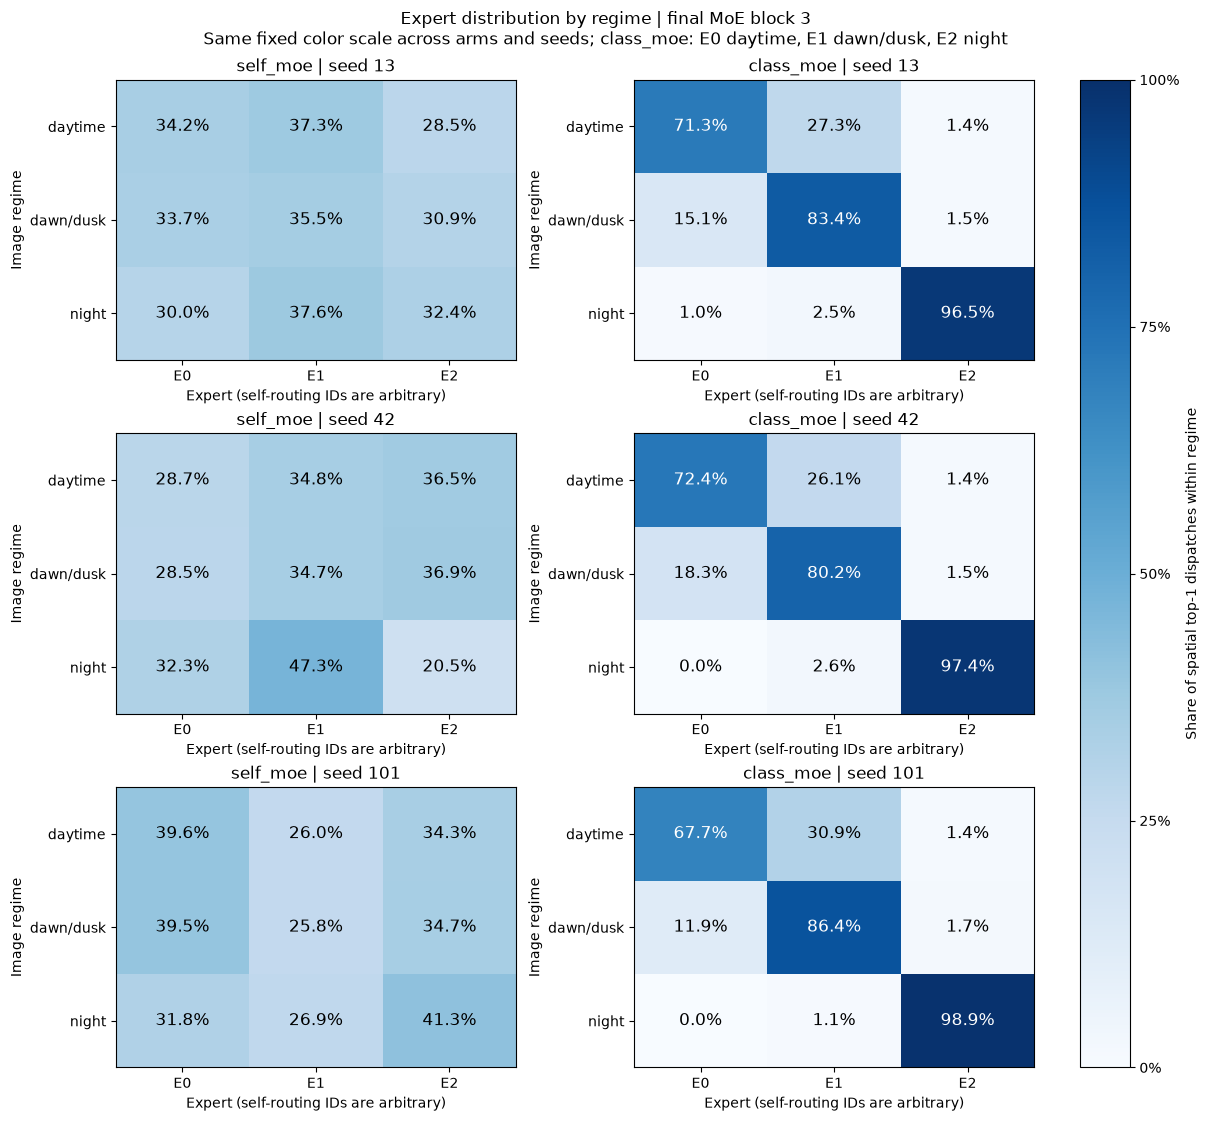

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display as show

# Set a saved run folder here to plot it without running training cells.
distribution_run_dir = None
if distribution_run_dir is None:
    if "run_dir" in globals():
        distribution_run_dir = Path(run_dir)
    else:
        distribution_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cafl4ds/configs").is_dir())
        distribution_files = sorted(
            (distribution_root / "outputs/moe-router-comparison").glob("*/expert_activation_frequency.csv")
        )
        if not distribution_files:
            raise FileNotFoundError("No saved expert statistics. Run the evaluation or select distribution_run_dir.")
        distribution_run_dir = distribution_files[-1].parent
distribution_data = pd.read_csv(Path(distribution_run_dir) / "expert_activation_frequency.csv")
distribution_regimes = ["daytime", "dawn/dusk", "night"]
distribution_arms = ["self_moe", "class_moe"]
distribution_data = distribution_data.loc[
    distribution_data["arm"].isin(distribution_arms) & distribution_data["regime"].isin(distribution_regimes)
].copy()
if distribution_data.empty or distribution_data["block"].nunique() != 1:
    raise ValueError("Expected nonempty expert statistics for one final MoE block.")
if distribution_data.duplicated(["seed", "arm", "regime", "expert"]).any():
    raise ValueError("Duplicate seed/arm/regime/expert rows would give ambiguous heatmap values.")
distribution_seeds = sorted(distribution_data["seed"].unique())
distribution_experts = sorted(distribution_data["expert"].unique())
distribution_block = int(distribution_data["block"].iloc[0])
distribution_fig, distribution_axes = plt.subplots(
    len(distribution_seeds), 2, figsize=(12, 3.7 * len(distribution_seeds)), squeeze=False, constrained_layout=True
)
for seed_row, distribution_seed in enumerate(distribution_seeds):
    for arm_column, distribution_arm in enumerate(distribution_arms):
        distribution_part = distribution_data.loc[
            (distribution_data["seed"] == distribution_seed) & (distribution_data["arm"] == distribution_arm)
        ]
        distribution_matrix = distribution_part.pivot(
            index="regime", columns="expert", values="token_activation_frequency"
        ).reindex(index=distribution_regimes, columns=distribution_experts)
        distribution_values = distribution_matrix.to_numpy()
        distribution_present = distribution_matrix.notna().all(axis=1)
        if not np.allclose(distribution_matrix.loc[distribution_present].sum(axis=1), 1):
            raise ValueError("Expert dispatch shares must sum to one within each regime.")
        distribution_ax = distribution_axes[seed_row, arm_column]
        distribution_image = distribution_ax.imshow(
            np.ma.masked_invalid(distribution_values), cmap="Blues", vmin=0, vmax=1, aspect="auto"
        )
        distribution_ax.set_xticks(range(len(distribution_experts)), [f"E{e}" for e in distribution_experts])
        distribution_ax.set_yticks(range(len(distribution_regimes)), distribution_regimes)
        distribution_ax.set_title(f"{distribution_arm} | seed {distribution_seed}")
        distribution_ax.set_xlabel("Expert (self-routing IDs are arbitrary)")
        distribution_ax.set_ylabel("Image regime")
        for regime_index, expert_index in np.ndindex(distribution_values.shape):
            distribution_value = distribution_values[regime_index, expert_index]
            distribution_ax.text(
                expert_index,
                regime_index,
                f"{distribution_value:.1%}" if np.isfinite(distribution_value) else "n/a",
                ha="center",
                va="center",
                color="white" if distribution_value > 0.55 else "black",
                fontsize=12,
            )
distribution_fig.colorbar(
    distribution_image,
    ax=distribution_axes.ravel().tolist(),
    label="Share of spatial top-1 dispatches within regime",
    ticks=[0, 0.25, 0.5, 0.75, 1],
    format="{x:.0%}",
)
distribution_fig.suptitle(
    f"Expert distribution by regime | final MoE block {distribution_block}\n"
    "Same fixed color scale across arms and seeds; class_moe: E0 daytime, E1 dawn/dusk, E2 night"
)
distribution_png = Path(distribution_run_dir) / "expert_distribution_by_regime.png"
distribution_fig.savefig(distribution_png, dpi=180)
distribution_fig.savefig(distribution_png.with_suffix(".pdf"))
distribution_data.to_csv(distribution_png.with_suffix(".csv"), index=False)
print(f"Saved regime heatmap from run: {Path(distribution_run_dir).name}")
print(distribution_png)
show(distribution_fig)
plt.close(distribution_fig)

In [ ]:
import ast as condition_ast
import hashlib as condition_hashlib
import json as condition_json
from pathlib import Path as ConditionPath

import numpy as condition_np
import pandas as condition_pd
import torch as condition_torch
from PIL import Image as ConditionImage
from torchvision.transforms import functional as condition_TF

from cafl4ds.models.vit import MoEViTEncoder as ConditionMoEEncoder
from cafl4ds.models.vit import TinyViTEncoder as ConditionDenseEncoder
from cafl4ds.ssl.factory import build_mae as condition_build_mae

# Frozen evaluation only. True includes rare scenes beyond the old 512-image CKA cap.
condition_run_dir = None
condition_labels_path = None
condition_use_all_query = True
condition_batch_size = 64
condition_prefer_cuda = True

condition_repo = next(
    p for p in [ConditionPath.cwd(), *ConditionPath.cwd().parents] if (p / "cafl4ds/configs").is_dir()
)
if condition_run_dir is None:
    if "run_dir" in globals() and (ConditionPath(run_dir) / "protocol.json").exists():
        condition_run_dir = ConditionPath(run_dir)
    else:
        condition_runs = sorted((condition_repo / "outputs/moe-router-comparison").glob("*/protocol.json"))
        if not condition_runs:
            raise FileNotFoundError("Select condition_run_dir with saved full-run checkpoints.")
        condition_run_dir = condition_runs[-1].parent
condition_run_dir = ConditionPath(condition_run_dir)
condition_protocol = condition_json.loads((condition_run_dir / "protocol.json").read_text(encoding="utf-8"))
condition_config = condition_protocol["protocol"]
condition_seeds = condition_config["seeds"]
condition_block = max(condition_config["moe_blocks"])
if condition_batch_size < 1 or condition_config["top_k"] != 1:
    raise ValueError("Use a positive inference batch size and the saved top-1 experiment.")
condition_query = condition_pd.read_csv(condition_run_dir / "query.csv")
if condition_query["clip_id"].duplicated().any():
    raise ValueError("The held-out query panel must contain unique clip IDs.")
condition_original_ids = condition_json.loads(
    (condition_run_dir / f"seed_{condition_seeds[0]}/self_moe/expert_probe_clip_ids.json").read_text(encoding="utf-8")
)
for condition_seed in condition_seeds:
    for condition_arm in ["self_moe", "class_moe"]:
        condition_ids = condition_json.loads(
            (condition_run_dir / f"seed_{condition_seed}/{condition_arm}/expert_probe_clip_ids.json").read_text(
                encoding="utf-8"
            )
        )
        if condition_ids != condition_original_ids:
            raise ValueError("Saved expert-probe identities differ between arms or seeds.")
condition_panel = (
    condition_query.copy()
    if condition_use_all_query
    else (condition_query.set_index("clip_id").loc[condition_original_ids].reset_index())
)
condition_panel["in_original_expert_probe"] = condition_panel["clip_id"].isin(condition_original_ids)
condition_excluded = {
    str(clip)
    for split in ["train", "support"]
    for clip in condition_pd.read_csv(condition_run_dir / f"{split}.csv")["clip_id"]
}
if set(condition_panel["clip_id"]) & condition_excluded:
    raise ValueError("Condition evaluation overlaps training or probe-support clips.")
if condition_labels_path is None and "weather" in condition_panel.columns:
    condition_labels = {
        row.clip_id: {"timeofday": row.regime, "scene": row.scene, "weather": row.weather}
        for row in condition_panel.itertuples()
    }
else:
    if condition_labels_path is None:
        condition_label_candidates = [
            parent / "labels/bdd100k_labels_images_val.json"
            for parent in ConditionPath(condition_panel["path"].iloc[0]).parents
        ]
        condition_labels_path = next((path for path in condition_label_candidates if path.exists()), None)
        if condition_labels_path is None:
            raise FileNotFoundError("Set condition_labels_path to the BDD validation image-attribute JSON.")
    condition_labels_path = ConditionPath(condition_labels_path)
    condition_labels = {
        ConditionPath(row["name"]).stem: row["attributes"]
        for row in condition_json.loads(condition_labels_path.read_text(encoding="utf-8"))
    }
if not set(condition_panel["clip_id"]).issubset(condition_labels):
    raise ValueError("Some held-out clips have no matching BDD condition annotations.")
condition_weather = []
for condition_row in condition_panel.itertuples():
    condition_attributes = condition_labels[condition_row.clip_id]
    if (condition_attributes.get("timeofday"), condition_attributes.get("scene")) != (
        condition_row.regime,
        condition_row.scene,
    ):
        raise ValueError("BDD time/scene labels disagree with the saved query manifest.")
    condition_weather.append(condition_attributes.get("weather", "(missing annotation)"))
condition_panel["weather"] = condition_weather

# Reuse strict saved-model loading and the exact notebook preprocessing, without running other cells.
condition_notebook = condition_json.loads(
    (condition_repo / "notebooks/moe_router_classification_comparison.ipynb").read_text(encoding="utf-8")
)
condition_nodes = {}
for condition_cell in condition_notebook["cells"]:
    if condition_cell["cell_type"] == "code":
        for condition_node in condition_ast.parse("".join(condition_cell["source"])).body:
            if isinstance(condition_node, condition_ast.FunctionDef) and condition_node.name in {
                "combined_load_models",
                "preprocess_rgb",
            }:
                condition_nodes[condition_node.name] = condition_node
if len(condition_nodes) != 2:
    raise ValueError("Missing saved-model or preprocessing helper definitions.")
condition_namespace = {
    "CombinedPath": ConditionPath,
    "combined_json": condition_json,
    "combined_torch": condition_torch,
    "CombinedDenseEncoder": ConditionDenseEncoder,
    "CombinedMoEEncoder": ConditionMoEEncoder,
    "combined_build_mae": condition_build_mae,
    "torch": condition_torch,
    "np": condition_np,
    "TF": condition_TF,
    "img_size": condition_config["img_size"],
}
exec(  # noqa: S102 - compile only these two named local function definitions, never notebook entry points.
    compile(condition_ast.Module(body=list(condition_nodes.values()), type_ignores=[]), "condition-helpers", "exec"),
    condition_namespace,
)
condition_checkpoint_hashes = {
    f"{seed}/{arm}": condition_hashlib.sha256(
        (condition_run_dir / f"seed_{seed}/{arm}/checkpoint_last.pt").read_bytes()
    ).hexdigest()
    for seed in condition_seeds
    for arm in ["dense", "self_moe", "class_moe"]
}
condition_image_stamps = [
    {
        "clip_id": row.clip_id,
        "size": ConditionPath(row.path).stat().st_size,
        "mtime_ns": ConditionPath(row.path).stat().st_mtime_ns,
    }
    for row in condition_panel.itertuples()
]
condition_contract = {
    "version": 1,
    "protocol_hash": condition_protocol["protocol_hash"],
    "analysis_block": condition_block,
    "all_query": condition_use_all_query,
    "clip_ids": condition_panel["clip_id"].tolist(),
    "checkpoint_sha256": condition_checkpoint_hashes,
    "labels_sha256": condition_hashlib.sha256(
        condition_json.dumps(condition_labels, sort_keys=True).encode()
    ).hexdigest(),
    "image_stamps": condition_image_stamps,
    "helper_source": condition_hashlib.sha256(
        condition_ast.dump(condition_ast.Module(body=list(condition_nodes.values()), type_ignores=[])).encode()
    ).hexdigest(),
}
condition_key = condition_hashlib.sha256(condition_json.dumps(condition_contract, sort_keys=True).encode()).hexdigest()[
    :12
]
condition_output = condition_run_dir / "condition_expert_analysis" / condition_key
condition_output.mkdir(parents=True, exist_ok=True)
condition_cache_path = condition_output / "per_image_expert_routing.csv"
condition_cache_manifest = condition_output / "manifest.json"
if condition_cache_manifest.exists():
    condition_saved = condition_json.loads(condition_cache_manifest.read_text(encoding="utf-8"))
    if condition_saved["contract"] != condition_contract or not condition_cache_path.exists():
        raise ValueError("Saved condition-cache metadata does not match this evaluation.")
    if condition_hashlib.sha256(condition_cache_path.read_bytes()).hexdigest() != condition_saved["routing_sha256"]:
        raise ValueError("Saved per-image routing cache differs from its recorded checksum.")
    condition_routing = condition_pd.read_csv(condition_cache_path)
    print(f"Reusing frozen condition routing: {condition_output}")
else:
    condition_device = condition_torch.device(
        "cuda" if condition_prefer_cuda and condition_torch.cuda.is_available() else "cpu"
    )
    condition_images = []
    for condition_row in condition_panel.itertuples():
        with ConditionImage.open(condition_row.path) as condition_image:
            condition_rgb = condition_np.array(condition_image.convert("RGB"))
        condition_images.append(condition_namespace["preprocess_rgb"](condition_rgb))
    condition_images = condition_torch.stack(condition_images)
    condition_rows = []
    condition_threads = condition_torch.get_num_threads()
    condition_models = {}
    try:
        if condition_device.type == "cpu":
            condition_torch.set_num_threads(2)
        with condition_torch.no_grad():
            for condition_seed in condition_seeds:
                condition_models = condition_namespace["combined_load_models"](
                    condition_run_dir, condition_seed, condition_config, condition_device
                )
                for condition_arm in ["self_moe", "class_moe"]:
                    condition_model = condition_models[condition_arm]
                    for condition_start in range(0, len(condition_panel), condition_batch_size):
                        condition_batch = condition_images[condition_start : condition_start + condition_batch_size].to(
                            condition_device
                        )
                        condition_probs = condition_model.encoder.routing(condition_batch)[condition_block][:, 1:, :]
                        condition_chosen = condition_torch.nn.functional.one_hot(
                            condition_probs.argmax(-1), condition_config["experts"]
                        )
                        condition_counts = condition_chosen.sum(1).cpu().numpy()
                        condition_soft_mass = condition_probs.sum(1).cpu().numpy()
                        for condition_i, condition_record in enumerate(
                            condition_panel.iloc[condition_start : condition_start + len(condition_batch)].to_dict(
                                "records"
                            )
                        ):
                            for condition_expert in range(condition_config["experts"]):
                                condition_rows.append(
                                    {
                                        **{
                                            key: condition_record[key]
                                            for key in [
                                                "clip_id",
                                                "regime",
                                                "weather",
                                                "scene",
                                                "in_original_expert_probe",
                                            ]
                                        },
                                        "arm": condition_arm,
                                        "seed": condition_seed,
                                        "block": condition_block,
                                        "expert": condition_expert,
                                        "spatial_tokens": condition_probs.shape[1],
                                        "selected_tokens": int(condition_counts[condition_i, condition_expert]),
                                        "probability_mass": float(condition_soft_mass[condition_i, condition_expert]),
                                    }
                                )
                    print(
                        f"Frozen routing: {condition_arm}, seed {condition_seed}; "
                        f"{len(condition_panel)} held-out images"
                    )
                for condition_model in condition_models.values():
                    condition_model.cpu()
                condition_models = {}
    finally:
        for condition_model in condition_models.values():
            condition_model.cpu()
        condition_torch.set_num_threads(condition_threads)
    condition_routing = condition_pd.DataFrame(condition_rows)
    condition_routing.to_csv(condition_cache_path, index=False)
    condition_panel.to_csv(condition_output / "panel_metadata.csv", index=False)
    condition_saved = {
        "contract": condition_contract,
        "images": len(condition_panel),
        "inference_device": str(condition_device),
        "routing_sha256": condition_hashlib.sha256(condition_cache_path.read_bytes()).hexdigest(),
    }
    condition_cache_manifest.write_text(condition_json.dumps(condition_saved, indent=2) + "\n", encoding="utf-8")
if condition_routing.duplicated(["arm", "seed", "clip_id", "expert"]).any():
    raise ValueError("Duplicate per-image expert observations.")
condition_dispatch_totals = condition_routing.groupby(["arm", "seed", "clip_id"])["selected_tokens"].sum()
condition_spatial_totals = condition_routing.groupby(["arm", "seed", "clip_id"])["spatial_tokens"].first()
if not condition_dispatch_totals.equals(condition_spatial_totals):
    raise ValueError("Per-image top-1 expert counts do not conserve spatial patches.")
print(
    f"Condition panel: {len(condition_panel)} held-out images; seeds {condition_seeds}; final block {condition_block}"
)

In [ ]:
import itertools as condition_itertools

import matplotlib.pyplot as condition_plt
from IPython.display import display as condition_show

# The cache above contains all seeds. Default detailed plots match the video's first seed.
condition_plot_seeds = [condition_seeds[0]]  # Use condition_seeds to display every trained seed.
condition_min_images = 5
condition_metric = "dispatch_share"  # Or "mean_probability" for continuous router preferences.
if condition_min_images < 1 or condition_metric not in {"dispatch_share", "mean_probability"}:
    raise ValueError("Select a positive image-count threshold and a supported routing metric.")
if not set(condition_plot_seeds).issubset(condition_seeds):
    raise ValueError("Choose plot seeds included in the saved frozen-evaluation cache.")
condition_regimes = ["daytime", "dawn/dusk", "night"]
condition_weather_order = sorted({attrs.get("weather", "(missing annotation)") for attrs in condition_labels.values()})
condition_scene_order = condition_config.get("probe_scenes", []) or sorted(
    condition_pd.read_csv(condition_run_dir / "support.csv")["scene"].dropna().unique()
)


def summarize_condition_routing(data: condition_pd.DataFrame, dimensions: list[str]) -> condition_pd.DataFrame:
    """Aggregate actual token counts and probability mass within each annotated condition."""
    measured = data.copy()
    measured["active"] = measured["selected_tokens"].gt(0).astype(int)
    grouped = (
        measured.groupby(["arm", "seed", "block", *dimensions, "expert"], dropna=False)
        .agg(
            images=("clip_id", "nunique"),
            selected_tokens=("selected_tokens", "sum"),
            spatial_tokens=("spatial_tokens", "sum"),
            probability_mass=("probability_mass", "sum"),
            active_images=("active", "sum"),
        )
        .reset_index()
    )
    grouped["dispatch_share"] = grouped["selected_tokens"] / grouped["spatial_tokens"]
    grouped["mean_probability"] = grouped["probability_mass"] / grouped["spatial_tokens"]
    grouped["image_activation_frequency"] = grouped["active_images"] / grouped["images"]
    sums = grouped.groupby(["arm", "seed", "block", *dimensions])[["dispatch_share", "mean_probability"]].sum()
    if not condition_np.allclose(sums.to_numpy(), 1, atol=1e-6):
        raise ValueError("Condition-level expert shares/probabilities must sum to one.")
    return grouped


def plot_condition_expert_heatmap(
    summary: condition_pd.DataFrame, dimensions: list[str], row_keys: list[tuple], seed: int, title: str, stem: str
) -> None:
    """Compare both arms on a fixed 0–100% scale with explicit image counts and sparse-cell masking."""
    if not row_keys:
        return
    selected = summary.loc[summary["seed"] == seed]
    index = condition_pd.MultiIndex.from_tuples(row_keys, names=dimensions)
    experts = list(range(condition_config["experts"]))
    sizes = selected.loc[selected["arm"] == "self_moe"].groupby(dimensions)["images"].first().reindex(index).fillna(0)
    cmap = condition_plt.get_cmap("Blues").copy()
    cmap.set_bad("#e6e8eb")
    fig, axes = condition_plt.subplots(
        1, 2, figsize=(13, max(5, len(row_keys) * 0.36 + 2.5)), sharey=True, constrained_layout=True
    )
    for ax, arm in zip(axes, ["self_moe", "class_moe"], strict=True):
        part = selected.loc[selected["arm"] == arm]
        matrix = part.pivot(index=dimensions, columns="expert", values=condition_metric).reindex(
            index=index, columns=experts
        )
        counts = part.groupby(dimensions)["images"].first().reindex(index).fillna(0)
        if not counts.equals(sizes):
            raise ValueError("Condition sample counts differ between the two MoE arms.")
        values = matrix.to_numpy(dtype=float, copy=True)
        values[counts.to_numpy() < condition_min_images, :] = condition_np.nan
        image = ax.imshow(condition_np.ma.masked_invalid(values), vmin=0, vmax=1, cmap=cmap, aspect="auto")
        ax.set_xticks(range(len(experts)), [f"E{expert}" for expert in experts])
        ax.set_yticks(
            range(len(row_keys)),
            [" | ".join(map(str, row)) + f"  (n={int(n)})" for row, n in zip(row_keys, counts, strict=True)],
            fontsize=9,
        )
        ax.set_title(f"{arm} | seed {seed}", fontsize=12)
        ax.set_xlabel("Expert")
        for row_index, expert_index in condition_np.ndindex(values.shape):
            value = values[row_index, expert_index]
            ax.text(
                expert_index,
                row_index,
                f"{value:.1%}" if condition_np.isfinite(value) else "—",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > 0.55 else "#30353b",
            )
        for row_index in range(1, len(row_keys)):
            if row_keys[row_index][0] != row_keys[row_index - 1][0]:
                ax.axhline(row_index - 0.5, color="#333333", linewidth=0.7)
    metric_label = "Spatial top-1 dispatch share" if condition_metric == "dispatch_share" else "Mean router probability"
    fig.colorbar(image, ax=axes.ravel().tolist(), label=metric_label, ticks=[0, 0.25, 0.5, 0.75, 1], format="{x:.0%}")
    fig.suptitle(
        f"{title} | seed {seed}, final MoE block {condition_block}\n"
        f"Same {len(condition_panel)} held-out images in both arms; "
        f"gray = n < {condition_min_images} or no observations",
        fontsize=12,
    )
    for suffix in ["png", "pdf"]:
        fig.savefig(condition_output / f"{stem}_seed_{seed}_{condition_metric}.{suffix}", dpi=170)
    condition_show(fig)
    condition_plt.close(fig)


condition_weather_stats = summarize_condition_routing(condition_routing, ["regime", "weather"])
condition_scene_stats = summarize_condition_routing(condition_routing, ["regime", "scene"])
condition_joint_stats = summarize_condition_routing(condition_routing, ["regime", "weather", "scene"])
for condition_name, condition_stats in [
    ("regime_weather", condition_weather_stats),
    ("regime_scene", condition_scene_stats),
    ("regime_weather_scene", condition_joint_stats),
]:
    condition_stats.to_csv(condition_output / f"{condition_name}_expert_distribution.csv", index=False)
for condition_seed in condition_plot_seeds:
    plot_condition_expert_heatmap(
        condition_weather_stats,
        ["regime", "weather"],
        list(condition_itertools.product(condition_regimes, condition_weather_order)),
        condition_seed,
        "Expert routing by time of day × weather",
        "weather",
    )
    plot_condition_expert_heatmap(
        condition_scene_stats,
        ["regime", "scene"],
        list(condition_itertools.product(condition_regimes, condition_scene_order)),
        condition_seed,
        "Expert routing by time of day × scene",
        "scene",
    )
    for condition_regime in condition_regimes:
        observed = condition_joint_stats.loc[condition_joint_stats["regime"] == condition_regime]
        keys = sorted(set(observed[["regime", "weather", "scene"]].itertuples(index=False, name=None)))
        plot_condition_expert_heatmap(
            condition_joint_stats,
            ["regime", "weather", "scene"],
            keys,
            condition_seed,
            f"Expert routing: {condition_regime} × weather × scene (observed combinations)",
            "joint_" + condition_regime.replace("/", "-"),
        )
print(
    f"Condition plots show seeds {condition_plot_seeds}; "
    f"per-image routing and CSV summaries contain all seeds {condition_seeds}."
)
print(f"Detailed condition heatmaps and sample counts: {condition_output}")

## Same-video comparison, using the experts nearest the output

Both MoEs process exactly the same chronological source frames. Each frame's mosaic shows **only the final MoE block**, with continuous expert-probability heatmaps and an overall top-1 patch map. IDs in the self-routing arm are arbitrary; use the cross-arm CKA matrix if aligning experts rather than assuming matching IDs. Classification-arm E0/E1/E2 are supervised toward daytime/dawn-dusk/night, respectively.

The dense model has no expert maps; its frozen scene predictions and masked MSE are included alongside the two MoEs in the per-frame CSV and quality timelines. Existing tunnel markers are manually inspected approximate events, not dataset labels. Framewise scene accuracy is not claimed without framewise ground truth.

Stacked area charts immediately above the players show each expert's percentage of spatial patch dispatches over time, with separate panels for the two MoE arms. Colors match the videos; each frame totals 100%, excluding CLS. The video heatmaps retain continuous routing probabilities.


In [12]:
import re as area_re
from pathlib import Path as AreaPath

import matplotlib.pyplot as area_plt
import numpy as area_np
import pandas as area_pd
from IPython.display import display as area_show


def video_area_measurements(
    data: area_pd.DataFrame, arm: str, columns: list[str], duration: float
) -> tuple[area_np.ndarray, area_np.ndarray]:
    """Validate one arm's recorded time series without renormalizing or interpolating measurements."""
    part = data.loc[data["arm"] == arm].sort_values("seconds")
    times = part["seconds"].to_numpy(dtype=float)
    shares = part[columns].to_numpy(dtype=float)
    if len(times) < 2 or not area_np.isfinite(times).all() or (area_np.diff(times) <= 0).any():
        raise ValueError("Video times must be finite, unique, and increasing.")
    if not area_np.isfinite(shares).all() or (shares < 0).any() or (shares > 1).any():
        raise ValueError("Expert dispatch shares must be finite and within [0, 1].")
    if not area_np.allclose(shares.sum(axis=1), 1, atol=1e-6):
        raise ValueError("Actual expert dispatch shares must sum to 100% at every frame.")
    if duration <= times[-1] or times[0] < 0:
        raise ValueError("Video duration must include the final displayed frame.")
    return times, shares


def plot_video_expert_areas(
    csv_path: AreaPath, title: str, duration: float, output_path: AreaPath, phases: list[dict] | None = None
) -> None:
    """Draw synchronized per-arm expert dispatch shares, preserving every measured video frame."""
    data = area_pd.read_csv(csv_path)
    expert_columns = sorted(
        [column for column in data if area_re.fullmatch(r"expert_\d+_dispatch_share", column)],
        key=lambda column: int(column.split("_")[1]),
    )
    if not expert_columns:
        raise ValueError(f"No expert dispatch shares found: {csv_path}")
    expert_ids = [int(column.split("_")[1]) for column in expert_columns]
    palette = ["#4c78a8", "#f58518", "#54a24b", "#e45756", "#b279a2", "#76b7b2", "#edc949", "#ff9da7"]
    colors = [palette[expert % len(palette)] for expert in expert_ids]
    labels = [f"Expert {expert}" for expert in expert_ids]
    arms = ["self_moe", "class_moe"]
    arm_titles = ["Self-routing MoE", "Classification-assisted MoE"]
    if not set(arms).issubset(set(data["arm"])):
        raise ValueError("Both MoE arms are required for the area comparison.")
    fig, axes = area_plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    common_times = None
    for ax, arm, arm_title in zip(axes, arms, arm_titles, strict=True):
        times, shares = video_area_measurements(data, arm, expert_columns, duration)
        if common_times is not None and not area_np.array_equal(common_times, times):
            raise ValueError("The two MoE arms have different video timestamps.")
        common_times = times
        # Hold each measured value through its displayed frame, including the last frame.
        display_times = area_np.append(times, duration)
        display_shares = area_np.vstack([shares, shares[-1]]) * 100
        ax.stackplot(display_times, display_shares.T, labels=labels, colors=colors, step="post", alpha=0.95)
        ax.set(title=arm_title, ylabel="Spatial patches routed (%)", ylim=(0, 100), xlim=(0, duration))
        ax.set_yticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
        ax.yaxis.grid(True, color="white", alpha=0.45, zorder=3)
        ax.spines[["top", "right"]].set_visible(False)
        if phases:
            for phase in phases:
                if phase["start_seconds"]:
                    ax.axvline(phase["start_seconds"], color="black", linestyle="--", linewidth=1.5)
    if phases:
        for phase in phases:
            axes[0].text(
                (phase["start_seconds"] + phase["end_seconds"]) / 2,
                0.96,
                phase["regime"],
                transform=axes[0].get_xaxis_transform(),
                ha="center",
                va="top",
                fontsize=10,
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 3},
            )
    axes[-1].set_xlabel("Video time (seconds)")
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=len(labels), frameon=False)
    fig.suptitle(title, fontsize=16, y=0.995)
    fig.text(
        0.5,
        0.015,
        "Stack height = spatial patches dispatched (%). Each frame totals 100%; CLS excluded.\n"
        "Colors match the video. Self-routing IDs are arbitrary; class targets: E0 daytime, E1 dawn/dusk, E2 night.",
        ha="center",
        fontsize=9,
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.91), h_pad=2)
    fig.savefig(output_path, dpi=160)
    fig.savefig(output_path.with_suffix(".pdf"))
    area_show(fig)
    area_plt.close(fig)


def directory_video_frames(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Read numbered extracted frames at their original capture rate."""
    path = Path(spec["path"])
    fps = float(spec.get("fps", 0))
    if not math.isfinite(fps) or fps <= 0:
        raise ValueError(f"{path}: frame directories require a positive source fps.")
    indexed = []
    for frame in path.iterdir():
        if frame.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue
        match = re.search(r"(\d+)$", frame.stem)
        if match is None:
            raise ValueError(f"Frame filename must end with its original frame index: {frame.name}")
        indexed.append((int(match.group(1)), frame))
    indexed.sort()
    if not indexed or len({i for i, _ in indexed}) != len(indexed):
        raise ValueError(f"Empty frame folder or duplicate numeric indices: {path}")
    for index, frame in indexed:
        seconds = (index - indexed[0][0]) / fps
        with Image.open(frame) as image:
            yield index, seconds, np.array(image.convert("RGB")), fps


def decoded_video_frames(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Decode every video frame in capture order and release the decoder on early exit."""
    path = Path(spec["path"])
    capture = cv2.VideoCapture(str(path))
    if not capture.isOpened():
        capture.release()
        raise OSError(f"Cannot open video: {path}")
    try:
        fps = float(capture.get(cv2.CAP_PROP_FPS))
        if not math.isfinite(fps) or fps <= 0:
            raise ValueError(f"Video has no valid source FPS: {path}")
        index, previous_seconds = 0, -1.0
        while True:
            success, bgr = capture.read()
            if not success:
                break
            reported = float(capture.get(cv2.CAP_PROP_POS_MSEC)) / 1000
            seconds = reported if math.isfinite(reported) and reported > previous_seconds else index / fps
            if seconds <= previous_seconds:
                raise ValueError(f"Nonmonotonic timestamps in {path} at frame {index}.")
            previous_seconds = seconds
            yield index, seconds, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), fps
            index += 1
    finally:
        capture.release()


def routing_video_samples(
    spec: dict[str, Any], source_reader: Callable, fps: float, max_seconds: float | None = None
) -> Iterator[tuple[int, float, float, np.ndarray]]:
    """Resample sequential source frames at constant output FPS using the preceding source frame."""
    reader = source_reader(spec)
    previous, output_time = None, 0.0
    try:
        for current in reader:
            if previous is None:
                previous = current
            while output_time < current[1] - 1e-8:
                if max_seconds is not None and output_time >= max_seconds - 1e-8:
                    return
                yield previous[0], previous[1], output_time, previous[2]
                output_time += 1 / fps
            previous = current
        if previous is None:
            raise ValueError(f"No frames decoded: {spec['path']}")
        while output_time < previous[1] + 1 / previous[3] - 1e-8:
            if max_seconds is not None and output_time >= max_seconds - 1e-8:
                return
            yield previous[0], previous[1], output_time, previous[2]
            output_time += 1 / fps
    finally:
        reader.close()


def expert_routing_mosaic(
    rgb: np.ndarray,
    routing: dict[int, np.ndarray],
    output_seconds: float,
    clip_id: str,
    top_k: int,
    mode: str = "probability",
    panel_width: int = 256,
    alpha: float = 0.65,
    active_experts: dict[int, np.ndarray] | None = None,
) -> np.ndarray:
    """Create original, per-expert heatmaps, and categorical winner panels for every MoE block."""
    if mode not in {"selected_weight", "probability", "dispatch"}:
        raise ValueError("mode must be selected_weight, probability, or dispatch.")
    blocks = sorted(routing)
    experts = next(iter(routing.values())).shape[-1]
    tile_h = panel_width * 9 // 16
    header_h, row_h = 36, tile_h + 56
    width, height = (experts + 2) * panel_width, 56 + len(blocks) * row_h + 40
    width += width % 2
    height += height % 2
    canvas = np.full((height, width, 3), 22, dtype=np.uint8)
    base = cv2.resize(rgb, (panel_width, tile_h), interpolation=cv2.INTER_AREA)
    palette = np.array(
        [
            [76, 120, 168],
            [245, 133, 24],
            [84, 162, 75],
            [228, 87, 86],
            [178, 121, 162],
            [118, 183, 178],
            [237, 201, 72],
            [255, 157, 167],
        ],
        dtype=np.uint8,
    )
    title = f"{clip_id} | {output_seconds:6.2f}s | actual unmasked routing | {mode} (fixed 0-1 scale)"
    cv2.putText(canvas, title, (12, 23), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (240, 240, 240), 1, cv2.LINE_AA)
    cv2.putText(
        canvas,
        "Spatial patch routing, not gradient attribution; expert IDs have no automatic regime meaning",
        (12, 44),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.43,
        (190, 190, 190),
        1,
        cv2.LINE_AA,
    )
    for row, block in enumerate(blocks):
        probabilities = routing[block]
        grid = math.isqrt(len(probabilities))
        if grid * grid != len(probabilities):
            raise ValueError(f"Expected a square spatial patch grid; got {len(probabilities)} tokens.")
        if active_experts is None:
            choices = torch.from_numpy(probabilities).topk(top_k, dim=-1).indices.numpy()
            selected = np.zeros_like(probabilities)
            np.put_along_axis(selected, choices, 1.0, axis=-1)
        else:
            selected = active_experts[block]
        winner = (selected.argmax(-1) if top_k == 1 else probabilities.argmax(-1)).reshape(grid, grid)
        y = 56 + row * row_h

        def panel(column: int, image: np.ndarray, heading: str, footer: str, y_offset: int = y) -> None:
            """Place one synchronized tile with an explicit summary label."""
            x = column * panel_width
            canvas[y_offset + header_h : y_offset + header_h + tile_h, x : x + panel_width] = image
            cv2.putText(
                canvas, heading, (x + 7, y_offset + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.43, (240, 240, 240), 1, cv2.LINE_AA
            )
            cv2.putText(
                canvas,
                footer,
                (x + 7, y_offset + header_h + tile_h + 14),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.36,
                (205, 205, 205),
                1,
                cv2.LINE_AA,
            )

        panel(0, base, f"Original | block {block}", f"{grid} x {grid} model patches; CLS excluded")
        for expert in range(experts):
            soft = probabilities[:, expert].reshape(grid, grid)
            active = selected[:, expert].reshape(grid, grid)
            values = active if mode == "dispatch" else soft
            strength = cv2.resize(values, (panel_width, tile_h), interpolation=cv2.INTER_LINEAR)
            active_pixels = cv2.resize(active, (panel_width, tile_h), interpolation=cv2.INTER_NEAREST)
            colored = cv2.cvtColor(
                cv2.applyColorMap(np.uint8(np.clip(strength, 0, 1) * 255), cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB
            )
            mask = np.ones_like(active_pixels) if mode == "probability" else active_pixels
            opacity = (alpha * mask)[..., None]
            overlay = np.uint8(base.astype(float) * (1 - opacity) + colored * opacity)
            share = selected[:, expert].mean() / top_k
            weight = (probabilities[:, expert] * selected[:, expert]).mean()
            panel(
                expert + 1,
                overlay,
                f"Expert {expert} | dispatch {100 * share:5.1f}%",
                f"mean selected gate weight: {weight:.3f}",
            )
        winner_colors = cv2.resize(
            palette[winner % len(palette)], (panel_width, tile_h), interpolation=cv2.INTER_NEAREST
        )
        winner_overlay = cv2.addWeighted(base, 0.45, winner_colors, 0.55, 0)
        panel(
            experts + 1,
            winner_overlay,
            f"Block {block} top-1 expert map",
            "Colors identify experts; not a strength scale",
        )
    legend_y = height - 30
    gradient = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (10, 1))
    bar = cv2.cvtColor(cv2.applyColorMap(gradient, cv2.COLORMAP_TURBO), cv2.COLOR_BGR2RGB)
    canvas[legend_y : legend_y + 10, 12:268] = bar
    cv2.putText(
        canvas,
        "0.0          0.25           0.5           0.75          1.0",
        (12, height - 6),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.30,
        (225, 225, 225),
        1,
        cv2.LINE_AA,
    )
    for expert in range(experts):
        x = 300 + expert * 115
        cv2.rectangle(
            canvas, (x, legend_y), (x + 14, legend_y + 14), tuple(int(v) for v in palette[expert % len(palette)]), -1
        )
        cv2.putText(
            canvas,
            f"Expert {expert}",
            (x + 20, legend_y + 12),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (225, 225, 225),
            1,
            cv2.LINE_AA,
        )
    return canvas

Comparing video: c2b6d359-e8c54604


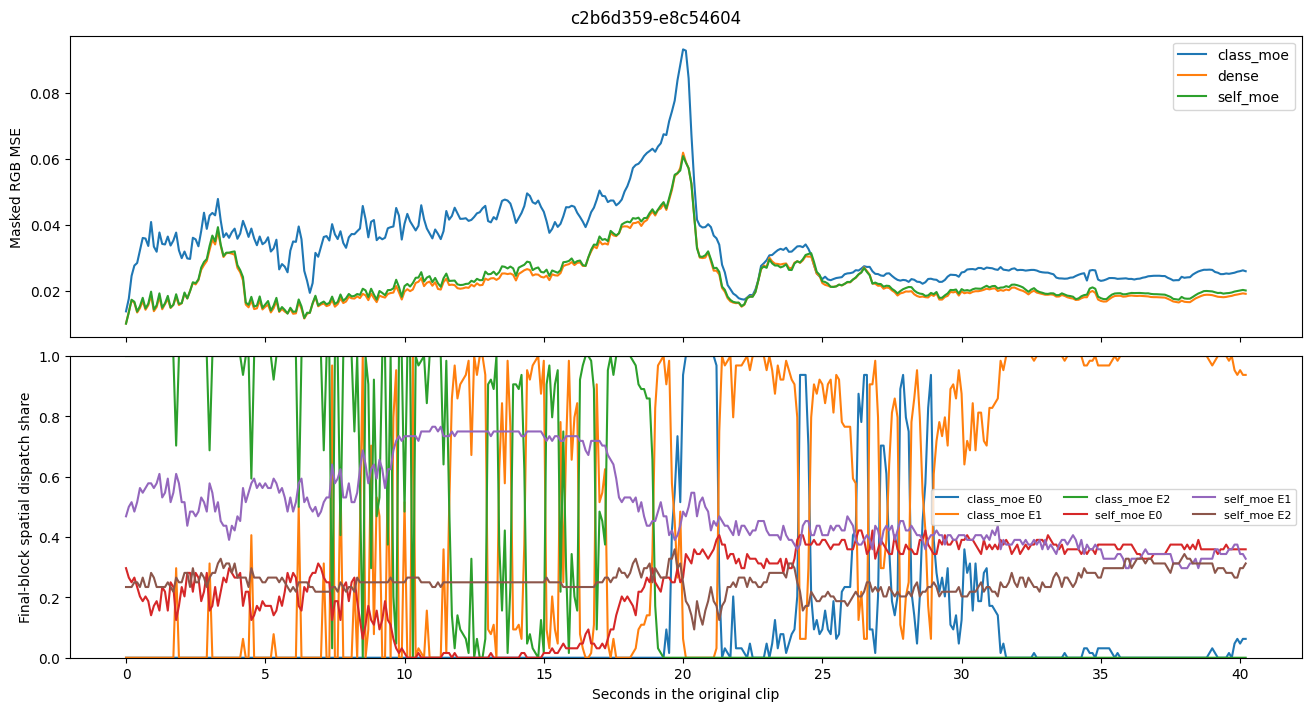

Comparing video: b56a0885-1c282ea8


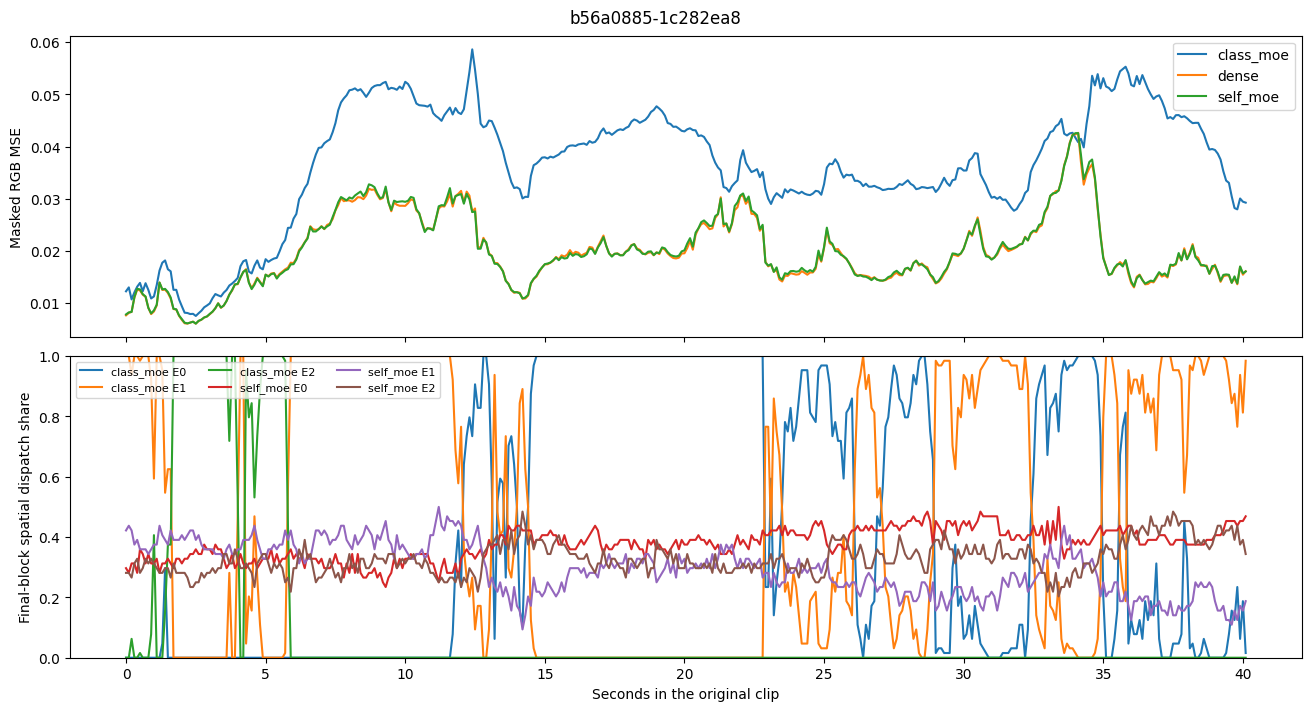

Comparing video: c05df6d2-9959222a


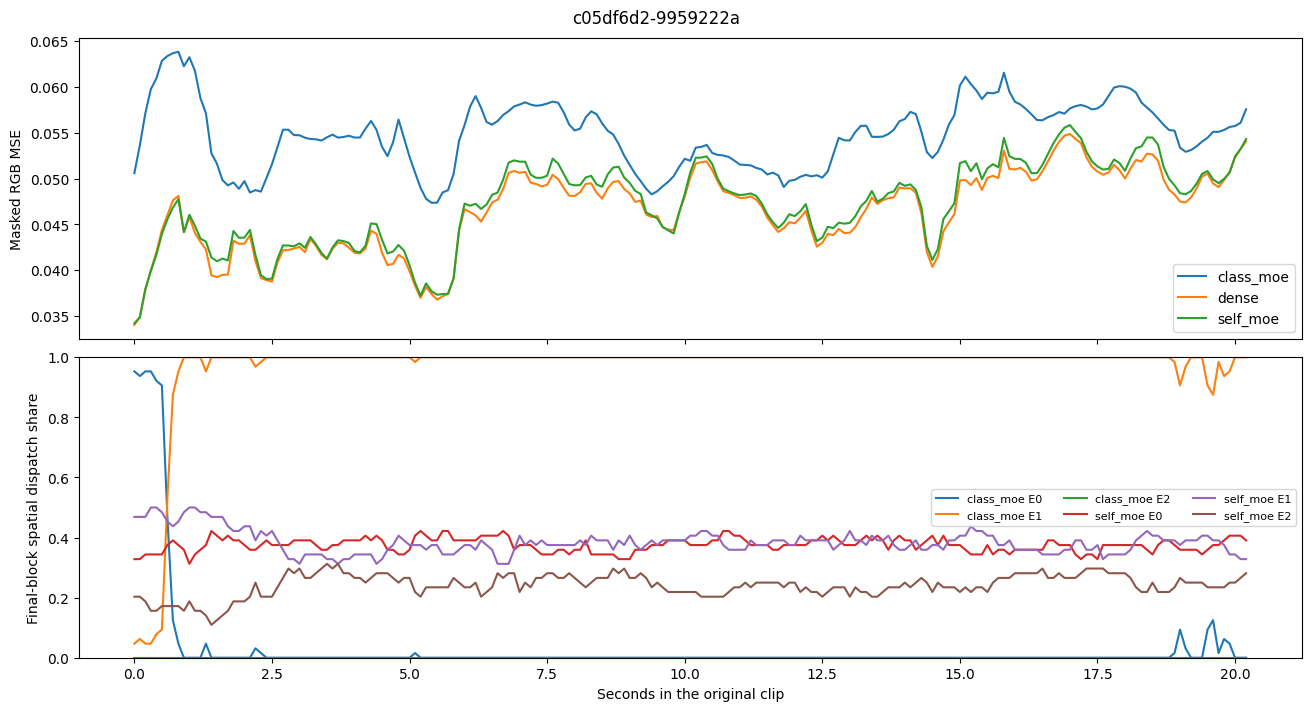

Comparing video: b4ef573f-8a8e0ea3


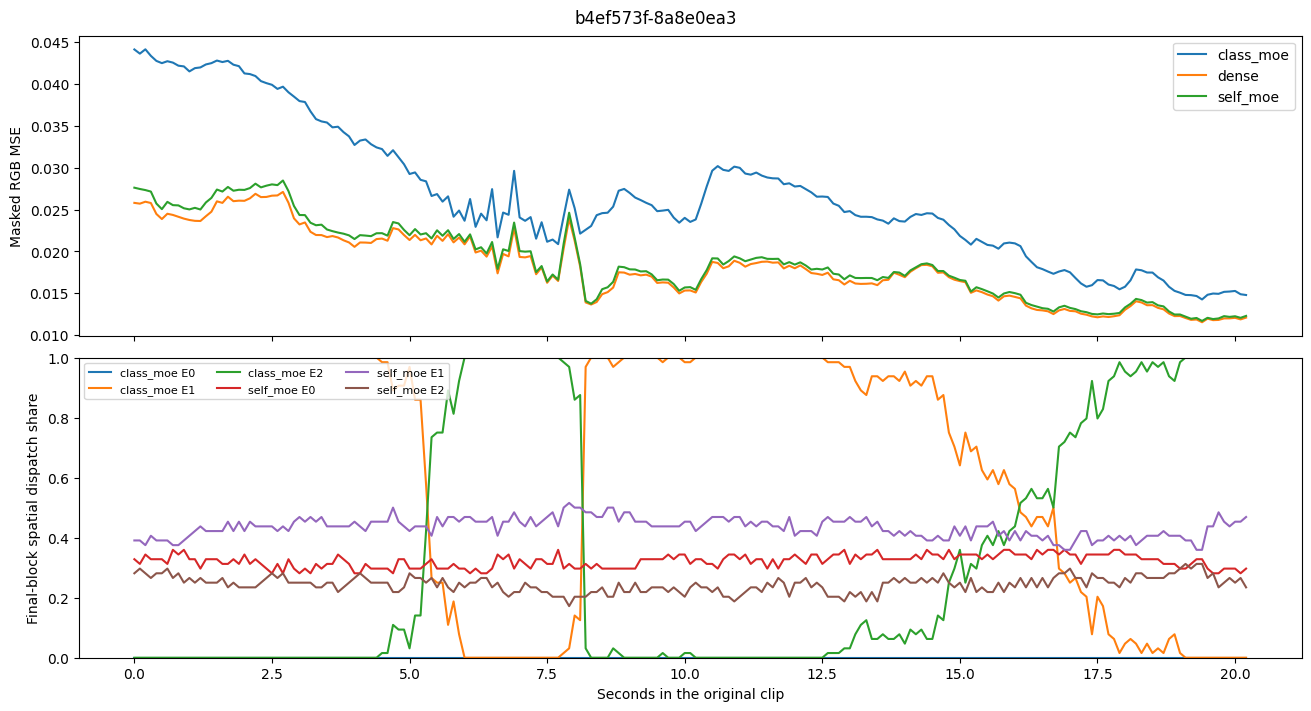

Comparing video: bf7f98e7-ca70ee34


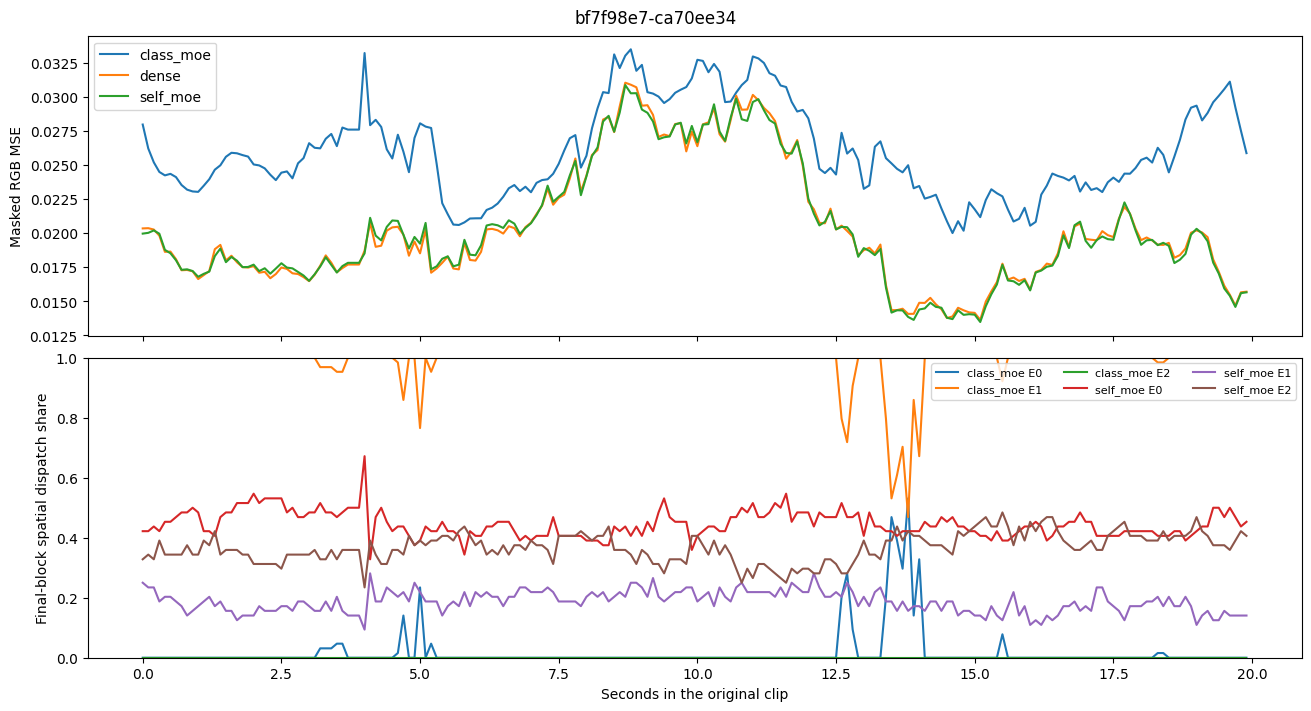

[Open synchronized MoE comparison: c2b6d359-e8c54604](../outputs/moe-router-comparison/20261028T174434487283Z/videos_seed_13/c2b6d359-e8c54604_paired.mp4)

[Open synchronized MoE comparison: b56a0885-1c282ea8](../outputs/moe-router-comparison/20261028T174434487283Z/videos_seed_13/b56a0885-1c282ea8_paired.mp4)

[Open synchronized MoE comparison: c05df6d2-9959222a](../outputs/moe-router-comparison/20261028T174434487283Z/videos_seed_13/c05df6d2-9959222a_paired.mp4)

[Open synchronized MoE comparison: b4ef573f-8a8e0ea3](../outputs/moe-router-comparison/20261028T174434487283Z/videos_seed_13/b4ef573f-8a8e0ea3_paired.mp4)

[Open synchronized MoE comparison: bf7f98e7-ca70ee34](../outputs/moe-router-comparison/20261028T174434487283Z/videos_seed_13/bf7f98e7-ca70ee34_paired.mp4)

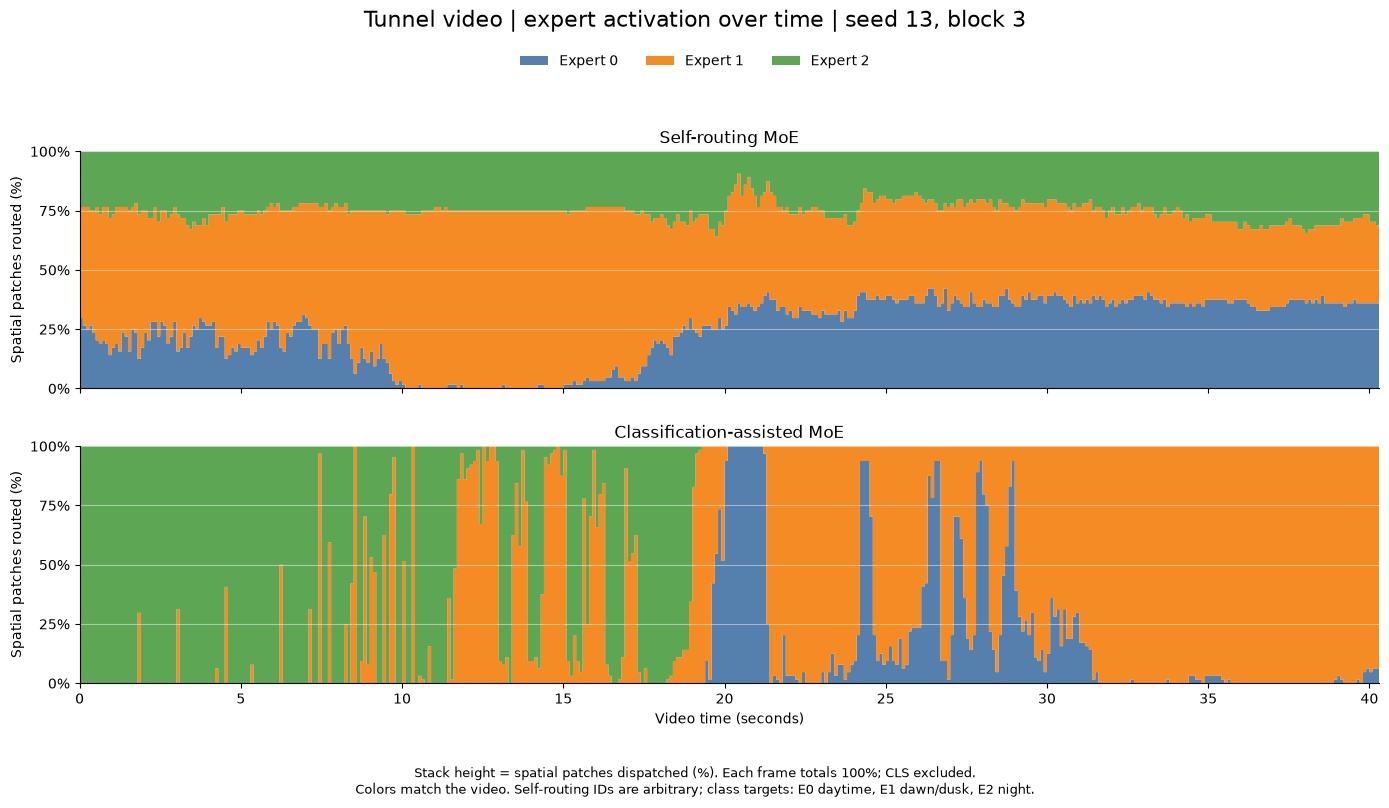

All comparison artifacts: c:\Users\muham\Documents\Project\cafl4ds\outputs\moe-router-comparison\20261028T174434487283Z


In [13]:
def comparison_source(spec: dict[str, Any]) -> Iterator[tuple[int, float, np.ndarray, float]]:
    """Decode original video/frame-folder order before common output-frame resampling."""
    return directory_video_frames(spec) if Path(spec["path"]).is_dir() else decoded_video_frames(spec)


@torch.no_grad()
def compare_video(spec: dict[str, Any]) -> dict[str, Any]:  # noqa: C901 - coordinate synchronized model evaluation/encoding.
    """Evaluate three models on shared frames; export two MoE rows for the final block only."""
    ffmpeg = shutil.which("ffmpeg")
    if ffmpeg is None:
        raise FileNotFoundError("FFmpeg with libx264 must be installed and on PATH.")
    folder = run_dir / f"videos_seed_{video_seed}"
    folder.mkdir(exist_ok=True)
    target = folder / f"{spec['clip_id']}_paired.mp4"
    if target.exists():
        raise FileExistsError(f"Video exists; move it or use a fresh run directory: {target}")
    reader = routing_video_samples(spec, comparison_source, video_fps, video_max_seconds)
    rows, process, count = [], None, 0
    modes = {arm: {module: module.training for module in model.modules()} for arm, model in video_models.items()}
    for model in video_models.values():
        model.to(device).eval()
    try:
        with target.with_suffix(".ffmpeg.log").open("w", encoding="utf-8") as log:
            finished = False
            while not finished:
                batch = []
                for _ in range(batch_size):
                    item = next(reader, None)
                    if item is None:
                        finished = True
                        break
                    batch.append(item)
                if not batch:
                    break
                images = torch.stack([preprocess_rgb(item[3]) for item in batch]).to(device)
                batch_data = {}
                for arm, model in video_models.items():
                    features = model.encode(images).cpu().numpy()
                    batch_data[arm] = {
                        "mse": masked_mse(model, images).cpu().numpy(),
                        "linear": video_readouts[arm]["linear"].predict(features),
                        "knn": video_readouts[arm]["knn"].predict(features),
                    }
                    if arm != "dense":
                        probability = model.encoder.routing(images)[analysis_block][:, 1:, :]
                        batch_data[arm]["probability"] = probability.cpu().numpy()
                        batch_data[arm]["selected"] = (
                            F.one_hot(probability.topk(top_k, -1).indices, num_experts).sum(-2).cpu().numpy()
                        )
                for index, (source_index, source_seconds, seconds, rgb) in enumerate(batch):
                    mosaics = []
                    for arm in ["self_moe", "class_moe"]:
                        values = batch_data[arm]
                        mosaic = expert_routing_mosaic(
                            rgb,
                            {analysis_block: values["probability"][index]},
                            seconds,
                            f"{arm} | {spec['clip_id']}",
                            top_k,
                            mode="probability",
                            panel_width=256,
                            active_experts={analysis_block: values["selected"][index]},
                        )
                        mosaics.append(mosaic)
                    frame = np.vstack(mosaics)
                    if process is None:
                        command = [
                            ffmpeg,
                            "-hide_banner",
                            "-loglevel",
                            "error",
                            "-n",
                            "-f",
                            "rawvideo",
                            "-pixel_format",
                            "rgb24",
                            "-video_size",
                            f"{frame.shape[1]}x{frame.shape[0]}",
                            "-framerate",
                            str(video_fps),
                            "-i",
                            "pipe:0",
                            "-an",
                            "-c:v",
                            "libx264",
                            "-preset",
                            "veryfast",
                            "-crf",
                            "22",
                            "-pix_fmt",
                            "yuv420p",
                            "-threads",
                            "2",
                            "-movflags",
                            "+faststart",
                            str(target),
                        ]
                        process = subprocess.Popen(command, stdin=subprocess.PIPE, stderr=log)  # noqa: S603 - fixed argv, no shell.
                    process.stdin.write(frame.tobytes())
                    for arm, values in batch_data.items():
                        row = {
                            "clip_id": spec["clip_id"],
                            "frame_index": source_index,
                            "source_seconds": source_seconds,
                            "seconds": seconds,
                            "arm": arm,
                            "masked_rgb_mse": float(values["mse"][index]),
                            "linear_scene": scene_names[int(values["linear"][index])],
                            "knn_scene": scene_names[int(values["knn"][index])],
                        }
                        if arm != "dense":
                            for expert in range(num_experts):
                                row[f"expert_{expert}_dispatch_share"] = float(
                                    values["selected"][index, :, expert].mean() / top_k
                                )
                                row[f"expert_{expert}_probability"] = float(
                                    values["probability"][index, :, expert].mean()
                                )
                        rows.append(row)
                    count += 1
            if process is None:
                raise ValueError("No video frames decoded.")
            process.stdin.close()
            if process.wait(timeout=120) != 0:
                raise RuntimeError(f"FFmpeg encoding failed: {target}")
    finally:
        reader.close()
        if process is not None and process.poll() is None:
            process.terminate()
            process.wait(timeout=15)
        for arm, model in video_models.items():
            for module, training in modes[arm].items():
                module.training = training
            model.cpu()
    data = pd.DataFrame(rows)
    data.to_csv(target.with_suffix(".csv"), index=False)
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
    for arm, part in data.groupby("arm"):
        axes[0].plot(part["seconds"], part["masked_rgb_mse"], label=arm)
        if arm != "dense":
            for expert in range(num_experts):
                axes[1].plot(part["seconds"], part[f"expert_{expert}_dispatch_share"], label=f"{arm} E{expert}")
    axes[0].set_ylabel("Masked RGB MSE")
    axes[1].set(xlabel="Seconds in the original clip", ylabel="Final-block spatial dispatch share", ylim=(0, 1))
    axes[0].legend()
    axes[1].legend(ncol=3, fontsize=8)
    fig.suptitle(spec["clip_id"])
    fig.savefig(target.with_suffix(".png"), dpi=130)
    plt.show()
    return {
        "clip_id": spec["clip_id"],
        "path": str(target),
        "frames": count,
        "fps": video_fps,
        "duration_seconds": count / video_fps,
        "seed": video_seed,
        "analysis_block": analysis_block,
        "map_mode": "continuous probability; overall top-1",
        "arm_order": ["self_moe", "class_moe"],
    }


video_reports = []
if export_comparison_videos:
    for spec in video_specs:
        print("Comparing video:", spec["clip_id"])
        video_reports.append(compare_video(spec))
    (run_dir / "video_manifest.json").write_text(dumps_valid(video_reports), encoding="utf-8")
    for report in video_reports:
        relative = Path(os.path.relpath(report["path"], repo_root / "notebooks")).as_posix()
        show(Markdown(f"[Open synchronized MoE comparison: {report['clip_id']}]({relative})"))
    if video_reports:
        first = Path(os.path.relpath(video_reports[0]["path"], repo_root / "notebooks")).as_posix()
        routing_area_report = video_reports[0]
        routing_area_csv = Path(routing_area_report["path"]).with_suffix(".csv")
        plot_video_expert_areas(
            routing_area_csv,
            f"Tunnel video | expert activation over time | seed {routing_area_report['seed']}, "
            f"block {routing_area_report['analysis_block']}",
            routing_area_report["duration_seconds"],
            routing_area_csv.with_name(routing_area_csv.stem + "_expert_area.png"),
        )
        show(Video(url=first, embed=False, width=1000))
print(f"All comparison artifacts: {run_dir}")

## Combined video: day → dawn/dusk → night, matching scene and weather

This additional comparison uses **three real held-out BDD validation clips**, all labeled **highway / clear**, stitched as 15 seconds daytime → 15 seconds dawn/dusk → 15 seconds night. The total is 45 seconds at 10 FPS, with cuts at 15 and 30 seconds. There are no artificial brightness changes or crossfades. These are different recordings, not one continuous sunset drive; geometry, traffic, and camera exposure can differ. BDD combines dawn and dusk into one label, so the middle clip retains that dataset label. Scene/weather/time labels are keyframe attributes, not independently annotated on every video frame.

Sources: daytime `c7d69f1b-e1ef4bf5`, dawn/dusk `b4ef573f-8a8e0ea3`, and night `c891763b-fea20b04`. Every source is checked against the saved run's train/support/query clip IDs before export. The selected source metadata and file hashes are stored in `outputs/bdd-day-dusk-night/matched_sources.json`.

Both MoEs see **identical source frames and timestamps**. The video stacks self-routing and classification routing, using only the final MoE block (nearest the output). Each expert has a continuous probability heatmap on the same fixed 0–1 scale; the overview remains top-1. A phase banner identifies the source changes. The dense baseline and both MoEs also receive the same saved reconstruction masks for the per-frame MSE comparison.

Run the following cell on saved full checkpoints without training or rerunning the tunnel exports. It saves the original combined footage, expert comparison MP4, frame provenance CSV, routing/reconstruction timeline, and a verified export manifest. Repeating an unchanged export reuses its checked files. Configure `combined_run_dir`, `combined_seed`, FPS, and seconds per regime at the top of the cell.

Stacked area charts immediately above the players show each expert's percentage of spatial patch dispatches over time, with separate panels for the two MoE arms. Colors match the videos; each frame totals 100%, excluding CLS. The video heatmaps retain continuous routing probabilities.


Completed daytime: 150 shared frames from c7d69f1b-e1ef4bf5


Completed dawn/dusk: 150 shared frames from b4ef573f-8a8e0ea3


Completed night: 150 shared frames from c891763b-fea20b04


[Original combined day → dawn/dusk → night footage](../outputs/moe-router-comparison/20261028T174434487283Z/combined_day_dusk_night_seed_13/19dd0279c989/combined_source.mp4)

[Synchronized self-routing versus classification heatmaps](../outputs/moe-router-comparison/20261028T174434487283Z/combined_day_dusk_night_seed_13/19dd0279c989/combined_expert_comparison.mp4)

[Expert routing and reconstruction timeline](../outputs/moe-router-comparison/20261028T174434487283Z/combined_day_dusk_night_seed_13/19dd0279c989/combined_timeline.png)

**Day → dawn/dusk → night: original combined footage**

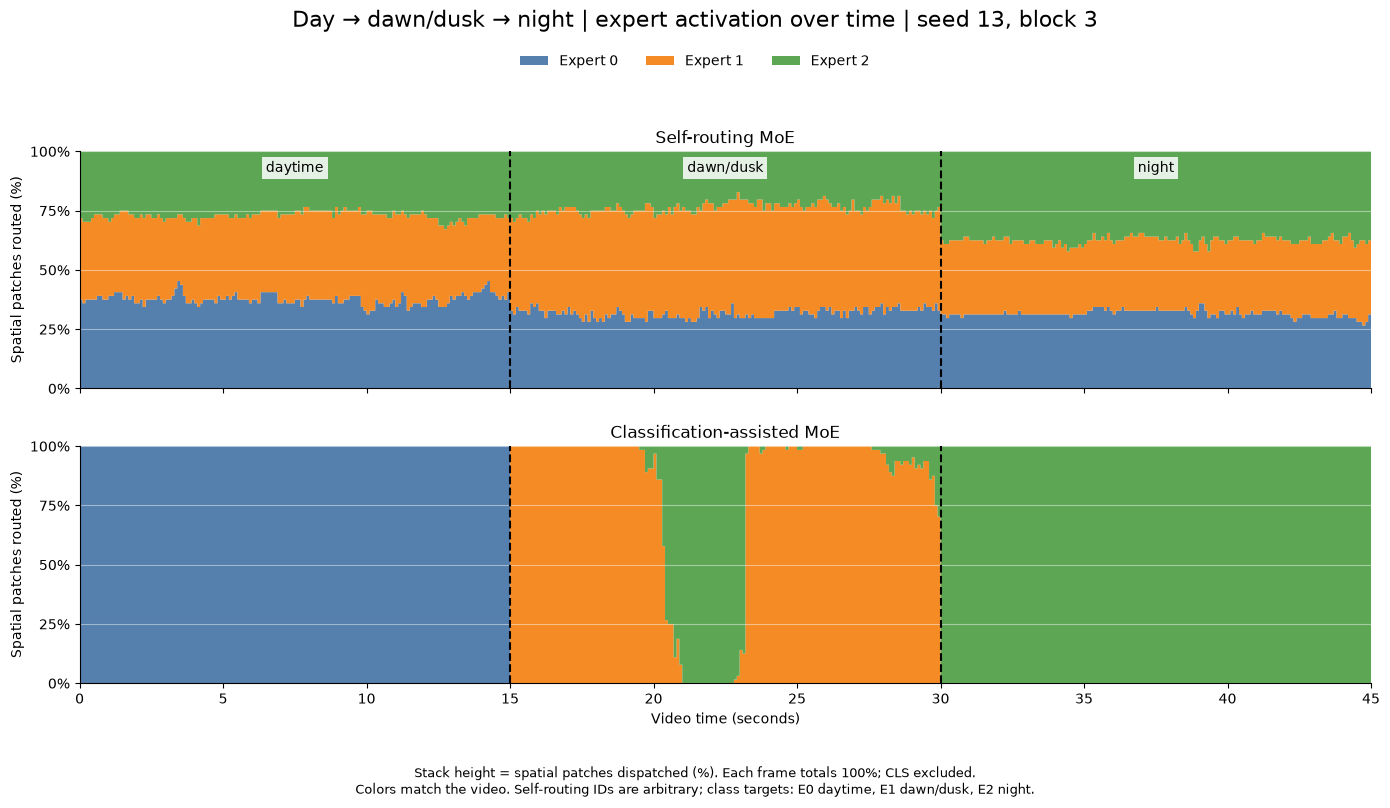

**Day → dawn/dusk → night: expert heatmap comparison**

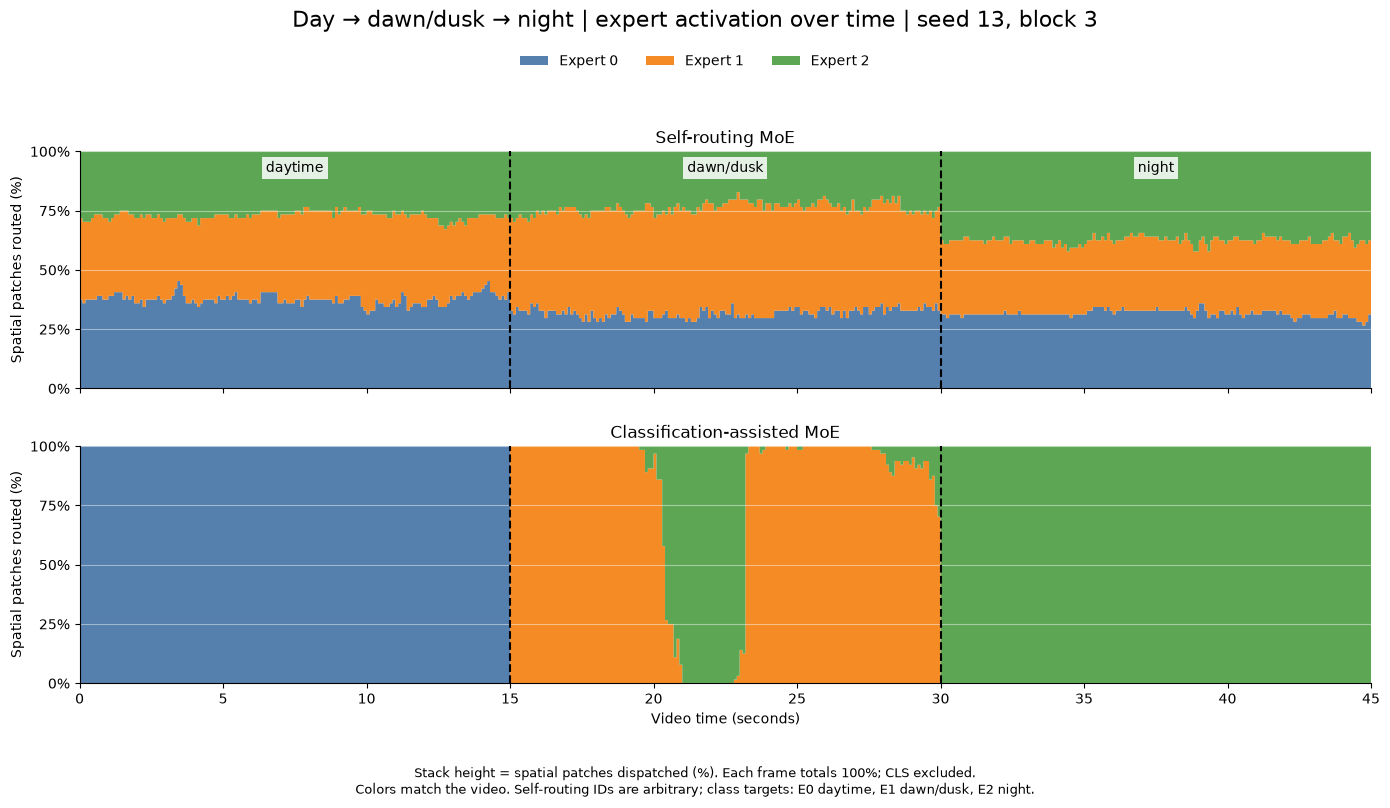

Exported 450 frames, 45.0s.

In [18]:
import ast as combined_ast
import hashlib as combined_hashlib
import json as combined_json
import math as combined_math
import os as combined_os
import re as combined_re
import shutil as combined_shutil
import subprocess as combined_subprocess
from collections.abc import Callable as CombinedCallable
from collections.abc import Iterator as CombinedIterator
from pathlib import Path as CombinedPath
from typing import Any as CombinedAny

import cv2 as combined_cv2
import matplotlib.pyplot as combined_plt
import numpy as combined_np
import pandas as combined_pd
import torch as combined_torch
from IPython.display import Markdown as CombinedMarkdown
from IPython.display import Video as CombinedVideo
from IPython.display import display as combined_show
from torchvision.transforms import functional as combined_TF

from cafl4ds.models.vit import MoEViTEncoder as CombinedMoEEncoder
from cafl4ds.models.vit import TinyViTEncoder as CombinedDenseEncoder
from cafl4ds.models.vit import patchify as combined_patchify
from cafl4ds.ssl.factory import build_mae as combined_build_mae

# This section works with saved checkpoints; it does not run any training cells.
combined_repo = next(p for p in [CombinedPath.cwd(), *CombinedPath.cwd().parents] if (p / "cafl4ds/configs").is_dir())
combined_run_dir = None  # Set a saved comparison-run folder to choose it explicitly.
combined_sources_path = combined_repo / "outputs/bdd-day-dusk-night/matched_sources.json"
combined_seed = None  # None selects the first training seed from the saved protocol.
combined_fps = 10.0
combined_seconds_per_regime = 15.0
combined_batch_size = 16
combined_prefer_cuda = True


def combined_load_helpers(config: dict, masks: combined_torch.Tensor) -> dict:
    """Reuse only the notebook's frozen preprocessing, routing renderer and reconstruction functions."""
    notebook = combined_json.loads(
        (combined_repo / "notebooks/moe_router_classification_comparison.ipynb").read_text(encoding="utf-8")
    )
    wanted = {
        "decoded_video_frames",
        "plot_video_expert_areas",
        "video_area_measurements",
        "expert_routing_mosaic",
        "preprocess_rgb",
        "masked_mse",
        "routing_video_samples",
    }
    nodes = {}
    for cell in notebook["cells"]:
        if cell["cell_type"] == "code":
            for node in combined_ast.parse("".join(cell["source"])).body:
                if isinstance(node, combined_ast.FunctionDef) and node.name in wanted:
                    nodes[node.name] = node
    if nodes.keys() != wanted:
        raise ValueError("The notebook's video/reconstruction helper definitions are incomplete.")
    namespace = {
        "torch": combined_torch,
        "np": combined_np,
        "cv2": combined_cv2,
        "math": combined_math,
        "re": combined_re,
        "Path": CombinedPath,
        "Any": CombinedAny,
        "Callable": CombinedCallable,
        "Iterator": CombinedIterator,
        "TF": combined_TF,
        "patchify": combined_patchify,
        "img_size": config["img_size"],
        "patch_size": config["patch_size"],
        "mask_ratio": config["mask_ratio"],
        "fixed_masks": masks,
        "AreaPath": CombinedPath,
        "area_np": combined_np,
        "area_pd": combined_pd,
        "area_plt": combined_plt,
        "area_re": combined_re,
        "area_show": combined_show,
    }
    # Function definitions only: do not execute notebook training/export entry points.
    exec(  # noqa: S102 - compile only named local function definitions, never cell entry points.
        compile(combined_ast.Module(body=list(nodes.values()), type_ignores=[]), "combined-video-helpers", "exec"),
        namespace,
    )
    return namespace


def combined_load_models(folder: CombinedPath, seed: int, config: dict, device: combined_torch.device) -> dict:
    """Load each saved full MAE with strict keys; do not update weights or reuse mutable training models."""
    models = {}
    encoder_config = {name: config[name] for name in ["img_size", "patch_size", "embed_dim", "depth", "num_heads"]}
    encoder_config["mlp_ratio"] = 2.0
    manifest = combined_json.loads((folder / "protocol.json").read_text(encoding="utf-8"))
    with combined_torch.random.fork_rng(devices=[]):
        for arm in ["dense", "self_moe", "class_moe"]:
            if arm == "dense":
                encoder = CombinedDenseEncoder(**encoder_config)
            else:
                encoder = CombinedMoEEncoder(
                    **encoder_config,
                    num_experts=config["experts"],
                    top_k=config["top_k"],
                    moe_blocks=config["moe_blocks"],
                    routing_level="token",
                    router_noise_std=config["router_noise_std"],
                )
            model = combined_build_mae(
                encoder,
                mask_ratio=config["mask_ratio"],
                decoder_dim=64,
                decoder_depth=2,
                decoder_heads=4,
                norm_pix_loss=False,
                aux_weight=0.0 if arm == "dense" else config["balance_weight"],
            )
            checkpoint = combined_torch.load(
                folder / f"seed_{seed}/{arm}/checkpoint_last.pt", map_location="cpu", weights_only=True
            )
            if (checkpoint["arm"], checkpoint["seed"], checkpoint["protocol_hash"]) != (
                arm,
                seed,
                manifest["protocol_hash"],
            ):
                raise ValueError("Saved model arm, seed or protocol mismatch.")
            if checkpoint["epoch"] != config["epochs"]:
                raise ValueError("The combined comparison requires completed checkpoints for all three arms.")
            model.load_state_dict(checkpoint["method"], strict=True)
            models[arm] = model.to(device).eval()
    return models


def combined_start_encoder(path: CombinedPath, width: int, height: int, fps: float) -> tuple:
    """Start one H.264 stream using a partial output so final files appear only on completion."""
    executable = combined_shutil.which("ffmpeg")
    if executable is None:
        raise FileNotFoundError("FFmpeg with libx264 must be installed and on PATH.")
    partial = path.with_name(path.stem + ".partial.mp4")
    log = path.with_suffix(".ffmpeg.log").open("w", encoding="utf-8")
    command = [
        executable,
        "-hide_banner",
        "-loglevel",
        "error",
        "-y",
        "-f",
        "rawvideo",
        "-pixel_format",
        "rgb24",
        "-video_size",
        f"{width}x{height}",
        "-framerate",
        str(fps),
        "-i",
        "pipe:0",
        "-an",
        "-c:v",
        "libx264",
        "-preset",
        "veryfast",
        "-crf",
        "22",
        "-pix_fmt",
        "yuv420p",
        "-threads",
        "2",
        "-movflags",
        "+faststart",
        str(partial),
    ]
    process = combined_subprocess.Popen(command, stdin=combined_subprocess.PIPE, stderr=log)  # noqa: S603
    return process, log, partial, path


def combined_plot_timeline(
    data: combined_pd.DataFrame, phases: list[dict], output: CombinedPath, seed: int, block: int
) -> None:
    """Show actual exposure, fixed-mask reconstruction, and final-block dispatch with visible source cuts."""
    fig, axes = combined_plt.subplots(4, 1, figsize=(14, 11), sharex=True, constrained_layout=True)
    original = data.loc[data["arm"] == "dense"]
    axes[0].plot(original["seconds"], original["mean_luma"], color="black")
    axes[0].set_ylabel("Mean RGB luma proxy")
    for arm, color in zip(["dense", "self_moe", "class_moe"], ["#667085", "#2474b7", "#d55e00"], strict=True):
        part = data.loc[data["arm"] == arm]
        axes[1].plot(part["seconds"], part["masked_rgb_mse"], color=color, label=arm)
    axes[1].set_ylabel("Masked RGB MSE")
    axes[1].legend(ncol=3)
    for ax, arm in zip(axes[2:], ["self_moe", "class_moe"], strict=True):
        part = data.loc[data["arm"] == arm]
        for expert, color in enumerate(["#4c78a8", "#f58518", "#54a24b"]):
            ax.plot(part["seconds"], part[f"expert_{expert}_dispatch_share"], color=color, label=f"E{expert}")
        ax.set(ylabel=f"{arm}\ndispatch share", ylim=(0, 1))
        ax.legend(ncol=3, loc="upper right")
    for phase, color in zip(phases, ["#f7e9a3", "#f2c2a0", "#bacce6"], strict=True):
        for ax in axes:
            ax.axvspan(phase["start_seconds"], phase["end_seconds"], color=color, alpha=0.15, zorder=0)
            ax.grid(alpha=0.15)
            if phase["start_seconds"]:
                ax.axvline(phase["start_seconds"], color="black", linestyle="--", linewidth=1)
        axes[0].text(
            (phase["start_seconds"] + phase["end_seconds"]) / 2,
            1.02,
            phase["regime"],
            ha="center",
            transform=axes[0].get_xaxis_transform(),
        )
    axes[-1].set(
        xlabel="Seconds in stitched video (dashed lines are cuts between recordings)",
        xlim=(0, phases[-1]["end_seconds"]),
    )
    fig.suptitle(f"Clear highway | day → dawn/dusk → night | seed {seed}, final MoE block {block}")
    fig.savefig(output, dpi=160)
    fig.savefig(output.with_suffix(".pdf"))
    combined_plt.close(fig)


@combined_torch.no_grad()
def export_combined_regime_video(  # noqa: C901 - keep synchronized streaming and process cleanup together.
    folder: CombinedPath,
    seed: int,
    sources: list[dict],
    fps: float,
    duration: float,
    batch_size: int,
    prefer_cuda: bool = True,
) -> dict:
    """Export the same three real source segments through both MoEs, with an original-video companion."""
    if fps <= 0 or duration <= 0 or batch_size < 1 or not combined_math.isclose(fps * duration, round(fps * duration)):
        raise ValueError("Use positive FPS/duration/batch size and an integer number of frames per phase.")
    manifest = combined_json.loads((folder / "protocol.json").read_text(encoding="utf-8"))
    config = manifest["protocol"]
    block = max(config["moe_blocks"])
    if config["experts"] != 3 or config["top_k"] != 1:
        raise ValueError("This section compares the three-expert top-1 spatial-routing experiment.")
    if [source["regime"] for source in sources] != ["daytime", "dawn/dusk", "night"]:
        raise ValueError("Order the source clips as daytime, dawn/dusk, night.")
    if len({(source["scene"], source["weather"]) for source in sources}) != 1:
        raise ValueError("Source clips must have identical BDD scene and weather labels.")
    excluded = {
        str(clip)
        for name in ["train", "support", "query"]
        for clip in combined_pd.read_csv(folder / f"{name}.csv")["clip_id"]
    }
    for source in sources:
        if source["clip_id"] in excluded or source.get("split") != "val":
            raise ValueError("A combined video overlaps still-image training/probe data or is not a validation clip.")
        if source["duration_seconds"] + 1e-5 < duration or source.get("start_seconds", 0) != 0:
            raise ValueError("Use a duration available in every clip, starting at source time zero.")
        if combined_hashlib.sha256(CombinedPath(source["path"]).read_bytes()).hexdigest() != source["sha256"]:
            raise ValueError("A source video differs from its verified manifest.")
    checkpoint_hashes = {
        arm: combined_hashlib.sha256((folder / f"seed_{seed}/{arm}/checkpoint_last.pt").read_bytes()).hexdigest()
        for arm in ["dense", "self_moe", "class_moe"]
    }
    contract = {
        "version": 1,
        "seed": seed,
        "fps": fps,
        "seconds_per_regime": duration,
        "sources": sources,
        "checkpoint_sha256": checkpoint_hashes,
        "analysis_block": block,
        "map_mode": "continuous probability with categorical top-1 overview",
    }
    digest = combined_hashlib.sha256(combined_json.dumps(contract, sort_keys=True).encode()).hexdigest()[:12]
    output = folder / f"combined_day_dusk_night_seed_{seed}" / digest
    output.mkdir(parents=True, exist_ok=True)
    report_path = output / "manifest.json"
    if report_path.exists():
        report = combined_json.loads(report_path.read_text(encoding="utf-8"))
        if report["contract"] != contract or not all(
            (output / name).exists() and combined_hashlib.sha256((output / name).read_bytes()).hexdigest() == checksum
            for name, checksum in report["artifact_sha256"].items()
        ):
            raise ValueError("Existing combined export differs from its manifest; inspect it before regenerating.")
        return report
    original_path = output / "combined_source.mp4"
    routing_path = output / "combined_expert_comparison.mp4"
    if original_path.exists() or routing_path.exists():
        raise FileExistsError("An incomplete combined export exists. Inspect it or choose a new output/run folder.")
    device = combined_torch.device("cuda" if prefer_cuda and combined_torch.cuda.is_available() else "cpu")
    masks = combined_torch.load(folder / "evaluation_masks.pt", map_location="cpu", weights_only=True)
    helpers = combined_load_helpers(config, masks)
    threads = combined_torch.get_num_threads()
    if device.type == "cpu":
        combined_torch.set_num_threads(2)
    models, encoders, rows, phases = {}, [], [], []
    count = 0
    try:
        models = combined_load_models(folder, seed, config, device)
        for phase_index, source in enumerate(sources):
            phase_start = phase_index * duration
            phases.append(
                {
                    "regime": source["regime"],
                    "clip_id": source["clip_id"],
                    "start_seconds": phase_start,
                    "end_seconds": phase_start + duration,
                }
            )
            reader = helpers["routing_video_samples"](source, helpers["decoded_video_frames"], fps, duration)
            phase_count = 0
            try:
                finished = False
                while not finished:
                    batch = []
                    for _ in range(batch_size):
                        item = next(reader, None)
                        if item is None:
                            finished = True
                            break
                        batch.append(item)
                    if not batch:
                        break
                    images = combined_torch.stack([helpers["preprocess_rgb"](item[3]) for item in batch]).to(device)
                    batch_values = {}
                    for arm, model in models.items():
                        values = {"mse": helpers["masked_mse"](model, images).cpu().numpy()}
                        if arm != "dense":
                            probability = model.encoder.routing(images)[block][:, 1:, :]
                            values["probability"] = probability.cpu().numpy()
                            values["selected"] = (
                                combined_torch.nn.functional.one_hot(probability.topk(1, -1).indices, config["experts"])
                                .sum(-2)
                                .cpu()
                                .numpy()
                            )
                        batch_values[arm] = values
                    for index, (source_frame, source_seconds, phase_seconds, rgb) in enumerate(batch):
                        seconds = phase_start + phase_seconds
                        mosaics = [
                            helpers["expert_routing_mosaic"](
                                rgb,
                                {block: batch_values[arm]["probability"][index]},
                                seconds,
                                f"{arm} | {source['clip_id']}",
                                1,
                                mode="probability",
                                panel_width=256,
                                active_experts={block: batch_values[arm]["selected"][index]},
                            )
                            for arm in ["self_moe", "class_moe"]
                        ]
                        body = combined_np.vstack(mosaics)
                        header = combined_np.full((48, body.shape[1], 3), 18, dtype=combined_np.uint8)
                        combined_cv2.putText(
                            header,
                            f"{source['regime'].upper()} | "
                            f"{source['weather'].upper()} {source['scene'].upper()} | "
                            f"combined {seconds:05.2f}s | source {source_seconds:05.2f}s",
                            (10, 19),
                            combined_cv2.FONT_HERSHEY_SIMPLEX,
                            0.53,
                            (245, 245, 245),
                            1,
                            combined_cv2.LINE_AA,
                        )
                        combined_cv2.putText(
                            header,
                            f"Stitched recordings: DAY 0-{duration:g}s > "
                            f"DAWN/DUSK {duration:g}-{2 * duration:g}s > "
                            f"NIGHT {2 * duration:g}-{3 * duration:g}s",
                            (10, 40),
                            combined_cv2.FONT_HERSHEY_SIMPLEX,
                            0.45,
                            (200, 200, 200),
                            1,
                            combined_cv2.LINE_AA,
                        )
                        frame = combined_np.vstack([header, body])
                        original = combined_cv2.resize(rgb, (1280, 720), interpolation=combined_cv2.INTER_AREA)
                        if not encoders:
                            encoders.append(combined_start_encoder(original_path, 1280, 720, fps))
                            encoders.append(combined_start_encoder(routing_path, frame.shape[1], frame.shape[0], fps))
                        encoders[0][0].stdin.write(original.tobytes())
                        encoders[1][0].stdin.write(frame.tobytes())
                        luma = float(
                            (
                                combined_cv2.resize(rgb, (160, 90)).astype(float)
                                / 255
                                @ combined_np.array([0.2126, 0.7152, 0.0722])
                            ).mean()
                        )
                        for arm, values in batch_values.items():
                            row = {
                                "output_frame": count,
                                "seconds": seconds,
                                "regime": source["regime"],
                                "scene": source["scene"],
                                "weather": source["weather"],
                                "source_clip_id": source["clip_id"],
                                "source_frame": source_frame,
                                "source_seconds": source_seconds,
                                "phase_seconds": phase_seconds,
                                "arm": arm,
                                "mean_luma": luma,
                                "masked_rgb_mse": float(values["mse"][index]),
                            }
                            if arm != "dense":
                                for expert in range(config["experts"]):
                                    row[f"expert_{expert}_probability"] = float(
                                        values["probability"][index, :, expert].mean()
                                    )
                                    row[f"expert_{expert}_dispatch_share"] = float(
                                        values["selected"][index, :, expert].mean()
                                    )
                            rows.append(row)
                        count += 1
                        phase_count += 1
            finally:
                reader.close()
            if phase_count != round(fps * duration):
                raise ValueError("A source clip ended before the requested phase duration.")
            print(f"Completed {source['regime']}: {phase_count} shared frames from {source['clip_id']}")
        for process, _log, _partial, _path in encoders:
            process.stdin.close()
            if process.wait(timeout=60) != 0:
                raise RuntimeError("FFmpeg failed; inspect the combined export logs.")
        for _process, _log, partial, path in encoders:
            partial.replace(path)
    finally:
        for process, log, _partial, _path in encoders:
            if process.poll() is None:
                process.terminate()
                process.wait(timeout=15)
            log.close()
        for model in models.values():
            model.cpu()
        combined_torch.set_num_threads(threads)
    data = combined_pd.DataFrame(rows)
    data.to_csv(output / "combined_frames.csv", index=False)
    combined_plot_timeline(data, phases, output / "combined_timeline.png", seed, block)
    artifacts = [
        "combined_source.mp4",
        "combined_expert_comparison.mp4",
        "combined_frames.csv",
        "combined_timeline.png",
        "combined_timeline.pdf",
    ]
    report = {
        "contract": contract,
        "output_dir": str(output),
        "frames": count,
        "duration_seconds": count / fps,
        "phases": phases,
        "continuous_recording": False,
        "brightness_modified": False,
        "artifact_sha256": {
            name: combined_hashlib.sha256((output / name).read_bytes()).hexdigest() for name in artifacts
        },
    }
    report_path.write_text(combined_json.dumps(report, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    return report


if combined_run_dir is None:
    if "run_dir" in globals() and (CombinedPath(run_dir) / "protocol.json").exists():
        combined_run_dir = CombinedPath(run_dir)
    else:
        combined_runs = sorted((combined_repo / "outputs/moe-router-comparison").glob("*/protocol.json"))
        if not combined_runs:
            raise FileNotFoundError("No saved comparison run found. Set combined_run_dir.")
        combined_run_dir = combined_runs[-1].parent
combined_run_dir = CombinedPath(combined_run_dir)
combined_config = combined_json.loads((combined_run_dir / "protocol.json").read_text(encoding="utf-8"))["protocol"]
if combined_seed is None:
    combined_seed = combined_config["seeds"][0]
if combined_seed not in combined_config["seeds"]:
    raise ValueError("Select a training seed present in the saved run.")
combined_sources = combined_json.loads(combined_sources_path.read_text(encoding="utf-8"))
combined_report = export_combined_regime_video(
    combined_run_dir,
    combined_seed,
    combined_sources,
    combined_fps,
    combined_seconds_per_regime,
    combined_batch_size,
    combined_prefer_cuda,
)
combined_output = CombinedPath(combined_report["output_dir"])
for combined_filename, combined_label in [
    ("combined_source.mp4", "Original combined day → dawn/dusk → night footage"),
    ("combined_expert_comparison.mp4", "Synchronized self-routing versus classification heatmaps"),
    ("combined_timeline.png", "Expert routing and reconstruction timeline"),
]:
    combined_link = CombinedPath(
        combined_os.path.relpath(combined_output / combined_filename, combined_repo / "notebooks")
    ).as_posix()
    combined_show(CombinedMarkdown(f"[{combined_label}]({combined_link})"))
combined_area_helpers = combined_load_helpers(
    combined_config,
    combined_torch.load(combined_run_dir / "evaluation_masks.pt", map_location="cpu", weights_only=True),
)
# Put the shared routing chart directly before each corresponding day/dusk/night player.
for combined_filename, combined_heading in [
    ("combined_source.mp4", "Day → dawn/dusk → night: original combined footage"),
    ("combined_expert_comparison.mp4", "Day → dawn/dusk → night: expert heatmap comparison"),
]:
    combined_player_url = CombinedPath(
        combined_os.path.relpath(combined_output / combined_filename, combined_repo / "notebooks")
    ).as_posix()
    combined_show(CombinedMarkdown(f"**{combined_heading}**"))
    combined_area_helpers["plot_video_expert_areas"](
        combined_output / "combined_frames.csv",
        "Day → dawn/dusk → night | expert activation over time | "
        f"seed {combined_report['contract']['seed']}, block {combined_report['contract']['analysis_block']}",
        combined_report["duration_seconds"],
        combined_output / "combined_expert_area.png",
        phases=combined_report["phases"],
    )
    combined_show(CombinedVideo(url=combined_player_url, embed=False, width=1100))
combined_show(
    CombinedMarkdown(f"Exported {combined_report['frames']} frames, {combined_report['duration_seconds']:.1f}s.")
)